# Chapter 3 Framework Development

**Notice**: You should create a new environment to learn this chapter. Run the following command on the terminal

In [ ]:
# conda create -n hello-agents python=3.11 -y

In [ ]:
# conda activate hello-agents

In [ ]:
# pip install "autogen-agentchat==0.7.4" "autogen-ext[openai]==0.7.4" python-dotenv

# 1. AutoGen

## 1.1 Core Mechanisms of AutoGen

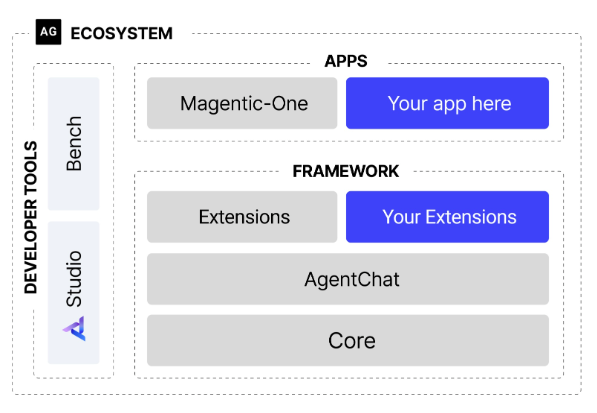

### 1.1.1 Evolution of Framework Structure
- Layered Design: 
  - autogen-core: it encapsulates core functions such as interaction with language models and message passing. Ensureing the stability and future extensibility of the framework
  - autogen-agentchat: Build on top of core, it provides high-level interfaces for developing conversational agent applications, simplifying the development process of multi-agent applications. This layering strategy makes each component's responsibilities clear and reduces system coupling 
- Asynchronous First: The new architecture (async/await). In multi-agent collaboration scenarios, network requests(calling LLM ) are the main time-consuming operations. Asynchronous allows the system to handle other tasks while waiting for one agent's response, thus avodiing thread blocking and improving concurrent processing capablities and system resource utilization efficiency.

### 1.2 Core Agent Components
- AssistantAgent: The main task solver, encapsulating a LLM. Its responsibility is to generate logical and knowldgebale replies based on conversation history, such as proposing plans, writing articles, or writing code. Through different system messages, we can assign it different expert roles.
- UserProxyAgent: It plays a dual role: both the "spokesperson" for human users, responsible for initiating tasks and conveying intentions, and a reliable "executor" that can be configured to execute code or call tools and feed results back to other agents. This design clearly distinguishes "thinking” from "action".


### 1.3 From GroupChatManager to Team

When tasks require multiple agents to collaborate, a mechanism is needed to coordinate the conversation process. GroupChatManager assumed this responsibility. In the new rchitecture, a more flexible Team or group chat concept is introduced, such as RoundRobinGroupchat

- Round Robin Group chat: It will have participating agents speak in turn according to a predefined order. This mode is very suitable for tasks with fixed processess, such as typical software development process

- Workflow:
  - Create a RoundRobinGroupChat instance and add all agents participating in collaboration
  - When a task starts, the group chat will activte the coreesponding agents in turn according to the preset order
  - The selected agent responds based on the current conversation context
  - The group chat adds the new reply to the conversation history and activates the next agent
  - This process continues until the maximum number of conversation rouds is reached or preset termination conditions are met


### 1.4 Example: A software Development Team

### 1.4.1 Buisness Problem
Develope an application for showing the current price of Bitcoin in real-time. This application covers the typical stage: Demand analysis,Technology selection, coding implementation to code review and final testing

### 1.4.2 Agent team roles

- Product Manager: transforming users' vague requirements into clear,executable development plans
- Engineer: Based on the development plan, reponsible for writing specific code
- Code Reviewer: reviewing code submitted by engineers to ensure its quality, readbility and robustness
- User Proxy: Represents the end user, initiates the inital task, and is responsible for executing and verifying the final delivered code.

### 1.4.3 Core Code Implementation

In [1]:
import os
import asyncio
from dotenv import load_dotenv

from autogen_ext.models.openai import OpenAIChatCompletionClient
from autogen_agentchat.agents import AssistantAgent, UserProxyAgent
from autogen_agentchat.teams import RoundRobinGroupChat
from autogen_agentchat.conditions import TextMentionTermination, MaxMessageTermination
from autogen_agentchat.ui import Console
# Load LLM_MODEL_ID / LLM_API_KEY / LLM_BASE_URL from .env
load_dotenv()

True

**Model Client Configuration** 

All LLM-based agents need a model client to interaact with language models. Autogen provides standard OpenAIChatCompletionClient that can conveniently interface with any model service compatible with OpenAI API

In [2]:
### For OpenAI (not run)
from autogen_ext.models.openai import OpenAIChatCompletionClient

def create_openai_model_client():
    """Create and configure OpenAI model client"""
    return OpenAIChatCompletionClient(
        model=os.getenv("LLM_MODEL_ID", "gpt-4o"),
        api_key=os.getenv("LLM_API_KEY"),
        base_url=os.getenv("LLM_BASE_URL", "https://api.openai.com/v1")
    )

In [2]:
def create_openai_model_client():
    """Create and configure the model client (DeepSeek through the OpenAI-compatible API)"""
    return OpenAIChatCompletionClient(
        model=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
        api_key=os.getenv("LLM_API_KEY"),
        base_url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
        # Required for non-OpenAI models: tells AutoGen what the model can do
        model_info={
            "function_calling": True,
            "max_tokens": 4096,
            "context_length": 32768,
            "vision": False,
            "json_output": True,
            "family": "deepseek",
            "structured_output": True,
        },
    )

**Definition of Agent Roles**  

System messages are like setting "behavioral guidlines" and "professsional knowledge bases" for agents. Specifying the agent's role, responsibilities and workflow

- **Product Manager**: Initiating the entire process. Not only defines its responsibilities but also standardizes the structure of its output and includes clear instructions to guide the conversation to the engineer

In [3]:
def create_product_manager(model_client):
    """Create product manager agent"""
    system_message = """You are an experienced product manager specializing in requirement analysis and project planning for software products.

Your core responsibilities include:
1. **Requirement Analysis**: Deeply understand user needs, identify core functions and boundary conditions
2. **Technical Planning**: Develop clear technical implementation paths based on requirements
3. **Risk Assessment**: Identify potential technical risks and user experience issues
4. **Coordination and Communication**: Communicate effectively with engineers and other team members

When receiving a development task, please analyze it according to the following structure:
1. Requirement understanding and analysis
2. Functional module division
3. Technology selection recommendations
4. Implementation priority sorting
5. Acceptance criteria definition

Please respond concisely and clearly, and say "Please engineer start implementation" after completing the analysis."""

    return AssistantAgent(
        name="ProductManager",
        model_client=model_client,
        system_message=system_message,
    )

- **Engineer**: Listing the engineer's technical expertise and specifying action steps after receiving a task, including instructions to guide the process to the code reviewer

In [4]:
def create_engineer(model_client):
    """Create software engineer agent"""
    system_message = """You are a senior software engineer skilled in Python development and web application construction.

Your technical expertise includes:
1. **Python Programming**: Proficient in Python syntax and best practices
2. **Web Development**: Expert in frameworks such as Streamlit, Flask, Django
3. **API Integration**: Rich experience in third-party API integration
4. **Error Handling**: Focus on code robustness and exception handling

When receiving a development task, please:
1. Carefully analyze technical requirements
2. Choose appropriate technical solutions
3. Write complete code implementation
4. Add necessary comments and explanations
5. Consider boundary cases and exception handling

Please provide complete runnable code and say "Please code reviewer check" after completion."""

    return AssistantAgent(
        name="Engineer",
        model_client=model_client,
        system_message=system_message,
    )

- **Code Reviewer**: Focusing on the code quality, safety and readability, ensuring a quality checkpint before code delivery

In [5]:
def create_code_reviewer(model_client):
    """Create code reviewer agent"""
    system_message = """You are an experienced code review expert focusing on code quality and best practices.

Your review focus includes:
1. **Code Quality**: Check code readability, maintainability, and performance
2. **Security**: Identify potential security vulnerabilities and risk points
3. **Best Practices**: Ensure code follows industry standards and best practices
4. **Error Handling**: Verify the completeness and rationality of exception handling

Review process:
1. Carefully read and understand code logic
2. Check code standards and best practices
3. Identify potential issues and improvement points
4. Provide specific modification suggestions
5. Evaluate overall code quality

Please provide specific review comments and say "Code review completed, please user proxy test" after completion."""

    return AssistantAgent(
        name="CodeReviewer",
        model_client=model_client,
        system_message=system_message,
    )

- **User Proxy**: Its description field clearly describes its responsibilities. It will issuing the TERMINATE instruction after the task is finally completed to normally end the entire collaboration process.

In [6]:
def create_user_proxy():
    """Create user proxy agent"""
    return UserProxyAgent(
        name="UserProxy",
        description="""User proxy, responsible for the following duties:
1. Propose development requirements on behalf of users
2. Execute final code implementation
3. Verify whether functions meet expectations
4. Provide user feedback and suggestions

Please reply TERMINATE after completing the test.""",
    )

- **Define Team Collaboratoin process**: The process is fixed(requirements->coding->review->testing), RoundRobinGroupChat(round-robin group chat) is the ideal choice. We add the four agents to the participant list in business logic order 
  - Participant Order: The order of the participants list determines the order in which agents speak
  - Termination condition: Termination_condition is key to controlling when the collaboration process ends. Here we set that when any message contains the keyword "TERMINATE", the conversation ends. This instruction is issued by USERPROXY after completing the final test
  - Maximum turns: is a safety value used to prevent conversatinos from falling into infinite loops and avoid unnecessary computation

In [7]:
async def run_software_development_team():
    """Run the software development team"""
    print("Initializing model client...")
    model_client = create_openai_model_client()

    print("Creating agent team...")
    product_manager = create_product_manager(model_client)
    engineer = create_engineer(model_client)
    code_reviewer = create_code_reviewer(model_client)
    user_proxy = create_user_proxy()

    # Define team chat and collaboration rules
    team_chat = RoundRobinGroupChat(
        participants=[
            product_manager,
            engineer,
            code_reviewer,
            user_proxy
        ],
        termination_condition=TextMentionTermination("TERMINATE", sources=["UserProxy"]) | 
        MaxMessageTermination(6),
        max_turns=20,
    )

    # Define task description
    task = """We need to develop a Bitcoin price display application with the following specific requirements:

Core functions:
- Display Bitcoin current price in real-time (USD)
- Display 24-hour price change trend (percentage and amount of increase/decrease)
- Provide price refresh function

Technical requirements:
- Use Streamlit framework to create web application
- Simple and beautiful interface, user-friendly
- Add appropriate error handling and loading status

Please team collaborate to complete this task, from requirement analysis to final implementation."""

    print("Starting AutoGen software development team collaboration...")
    print("=" * 60)

    # Asynchronously execute team collaboration and stream output conversation process
    result = await Console(team_chat.run_stream(task=task))

    print("=" * 60)
    print("Team collaboration completed!")
    print(f"Stop reason: {result.stop_reason}")

    await model_client.close()
    return result


# Main program entry
result = await run_software_development_team()


Initializing model client...
Creating agent team...
Starting AutoGen software development team collaboration...
---------- TextMessage (user) ----------
We need to develop a Bitcoin price display application with the following specific requirements:

Core functions:
- Display Bitcoin current price in real-time (USD)
- Display 24-hour price change trend (percentage and amount of increase/decrease)
- Provide price refresh function

Technical requirements:
- Use Streamlit framework to create web application
- Simple and beautiful interface, user-friendly
- Add appropriate error handling and loading status

Please team collaborate to complete this task, from requirement analysis to final implementation.
---------- ThoughtEvent (ProductManager) ----------
We need answer as PM. Need structure, concise, say "Please engineer start implementation" after analysis. Need analyze requirements, functional modules, tech selection, priority, acceptance criteria. Need maybe mention team collaboration? 

Enter your response: TERMINATE   [typed automatically by the runner]
We need to review the code that's been provided. Let me carefully analyze the implementation against the requirements and best practices.

Let me go through the code:

1. **App structure**: The code has a clean separation: config, errors, data acquisition, validation, formatting, presentation, and entry point.

2. **Potential issues**:

a) `st.cache_data` on `get_bitcoin_data()` — the function calls `_fetch_market_payload()` which uses `requests.get`. Caching works. But note: `.clear()` is called on the cached function. That's correct usage.

b) The spinner: `with st.spinner(...)` wraps the `get_bitcoin_data()` call. But since it's cached, on subsequent loads with cache hit, the spinner will be shown but immediately gone. That's fine.

c) **Issue**: The `st.spinner` is shown even when the data comes from cache. Minor UX, not a bug.

d) **Issue**: `render_price_cards` uses `st.write("")` for spacing. Fine.

e) **Potent

### 1.5 Advantages and limitations

**Advndvantages:**
1. No need to design comlex state machines or control flow logic for the agent team, but naturally map a complete software development process to conversations between main roles. 
2. Giving every agents professional roles by system messages, enabling them reused in different projects
3. RoundRobinGroupChat provides a clear, predictable process; UserProxyAgent is the natural interface of human-on-the-loop 

**Limitations:**
1. The conversations based on LLM are uncertain. Agents may produce replies that deviate from expectations, causing conversations to go in unexpected directions or even fall into loops
2. When the work results of the agent team do not meet expectations, the debugging process can be very tricky.

## 2. AgentScope

Agentscope is like an engineering-first multi-agent platform. It provies intuitive and easy-to-use programming interface and has built-in enterprise-level features such as distributed deployment, fault recovery and observability, making it parrticularly suitable for bulidng production environmnet applications that need to run suably for a long time

### 2.1 Design of AgentScope
**Layered Architecture System**: AgentScope adopts a clear layered modular design, forming a complete agent development ecosystem from bottom-level basic components to top-level application orchestration

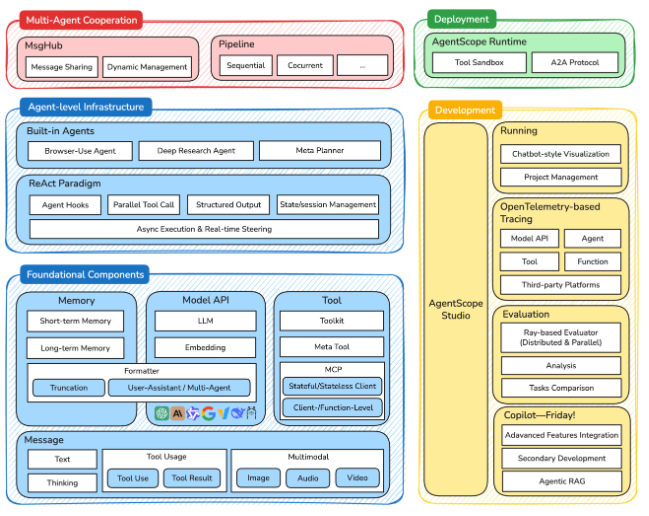

**(1) Layered Architecture**

| Layer | Components | Role |
|---|---|---|
| Foundational Components | Message, Memory, Model API, Tool | A unified message format, memory management, model calls, and tools |
| Agent-level Infrastructure | Pre-built agents and a built-in ReAct paradigm | Supports hooks, parallel tool calling, state management, and native async execution |
| Multi-Agent Cooperation | **MsgHub** (message center) and **Pipeline** | Routes messages and orchestrates execution, either sequential or concurrent |
| Deployment & Development | AgentScope Runtime and AgentScope Studio | A production-grade runtime and a visual development toolchain |

**(2) Message-Driven**
All agent interactions aare abstracted as the sending and receving of messaages, rather than traditionl function caalls

In [8]:
from agentscope.message import Msg

# Standard structure of message
message = Msg(
    name="Alice",           # Sender name
    content="Hello, Bob!",  # Message content
    role="user",            # Role type
    metadata={              # Metadata information
        "timestamp": "2024-01-15T10:30:00Z",
        "message_type": "text",
        "priority": "normal"
    }
)

- Asynchronous Decoupling: The sender and receiver of messages are decoupled in time, without needing to wait for each other, supporting high-concurrency scenarios
- Location Transparency: Agents do not need to care whether another agent is in a local process or on a remote server; the message system automatically handles routing 
- observbility: Every message can be logged, tracked, and analyzed, greatly simplifying debuggin and moniroring of complex systems
- Reliability: Messages can be persistently stored and retried. Even if the system fails, it can ensure the eventual consistency of interactions, improving the system's fault tolerance.


**(3)Agent lifecycle management**:  
In AgentScope, each agent has a clear lifecycle (initialization, running, pausing, destruction, etc.) and is implemented based on a unified base class AgentBase
  

In [9]:
from agentscope.agent import AgentBase
from agentscope.message import Msg


class GameModerator(AgentBase):
    """Game moderator"""

    def __init__(self) -> None:
        super().__init__()
        self.name = "Moderator"
        self.game_log: List[str] = []

    async def announce(self, content: str) -> Msg:
        """Make a game announcement"""
        msg = Msg(
            name=self.name,
            content=f"📢 {content}",
            role="system"
        )
        self.game_log.append(content)
        await self.print(msg)
        return msg

This pattern separates the agent's internal logic from external commnication. Developers only need to define how the agent "thinks and responds" in the Reply method

**(4) Message passing Mechanism**

AgentScope has built-in Message Center, which is the hub of the entire message-driven architecture.
- Flexible message routing: supporting point-to-point, broadcast and multicast, and can build flexible and complex interaction networks.
- Message Persistence: save all messages to databases, ensuring that the state of long-running tasks can be recovered
- Native Distributed Support: This is a signature feature of AgentScope. Agents can be deployed on different processes or servers, and MSHub will automatically handle cross-node communication through PRC, completely transparet to developers
  

### 2.2 Game to show these features

Unlike traditional Werewolf, our "Three Kingdoms Werewolf" introduces classic characters such as Liu Bei, Guan Yu, and Zhuge Liang into the game. Each agent not only has to complete the basic tasks of Werewolf (such as werewolf killing, seer verification, villager reasoning) but also embodies the personality traits and behavior patterns of the corresponding Three Kingdoms characters. This design allows us to observe AgentScope's performance in handling multi-level role modeling.

**(1) The design of architecture and core commponents**

- Game Control Layer: A ThreeKingdomsWerewolfGame class serves as the main controller of the game, responsible for maintaining global state (such as player survival list, current game stage), advancing the game process (calling night phase, day phase), and judging victory or defeat.
- Agent Interaction Layer: Completely driven by MsgHub. All communication between agents, whether it's secret negotiations between werewolves or public debates during the day, is routed and distributed through the message center.
- Role Modeling Layer: Each player is an instance based on DialogAgent. Through carefully designed system prompts, we inject each agent with the dual identity of "game role" and "Three Kingdoms personality."

In [10]:
# -*- coding: utf-8 -*-
"""Three Kingdoms Werewolf: role definitions"""
from typing import List


class GameRoles:
    """Game role manager"""

    ROLES = {
        "Werewolf": {
            "description": "Werewolf",
            "ability": "You can kill one player at night.",
            "win_condition": "Eliminate all good players, or equal their number",
            "team": "Werewolf camp"
        },
        "Seer": {
            "description": "Seer",
            "ability": "Each night you can check one player's identity.",
            "win_condition": "Eliminate all werewolves",
            "team": "Good camp"
        },
        "Witch": {
            "description": "Witch",
            "ability": "You have one antidote and one poison: you can save a player or kill one.",
            "win_condition": "Eliminate all werewolves",
            "team": "Good camp"
        },
        "Hunter": {
            "description": "Hunter",
            "ability": "When voted out, you can shoot and take one player down with you.",
            "win_condition": "Eliminate all werewolves",
            "team": "Good camp"
        },
        "Villager": {
            "description": "Villager",
            "ability": "No special ability; you rely on reasoning and voting.",
            "win_condition": "Eliminate all werewolves",
            "team": "Good camp"
        },
        "Guard": {
            "description": "Guard",
            "ability": "Each night you can protect one player from the werewolves.",
            "win_condition": "Eliminate all werewolves",
            "team": "Good camp"
        }
    }

    CHARACTER_TRAITS = {
        "Liu Bei": "Benevolent and generous, good at uniting people, speaks gently and politely",
        "Guan Yu": "Loyal and upright, speaks directly, values brotherhood",
        "Zhang Fei": "Bold and outspoken, speaks loudly and bluntly, easily provoked",
        "Zhuge Liang": "Extraordinarily wise, analyzes thoroughly, chooses words carefully",
        "Zhao Yun": "Loyal and brave, speaks briefly and firmly",
        "Cao Cao": "Ambitious and strategic, skilled at scheming, speaks sharply",
        "Sima Yi": "Far-sighted and deeply calculating, speaks in a reserved way",
        "Zhou Yu": "Brilliant and a little proud, analyzes precisely",
        "Sun Quan": "Young and capable, decisive, speaks resolutely"
    }

    @classmethod
    def get_role_desc(cls, role: str) -> str:
        """Get the role description"""
        return cls.ROLES.get(role, {}).get("description", "Unknown role")

    @classmethod
    def get_role_ability(cls, role: str) -> str:
        """Get the role ability"""
        return cls.ROLES.get(role, {}).get("ability", "No special ability.")

    @classmethod
    def get_character_trait(cls, character: str) -> str:
        """Get the character's personality traits"""
        return cls.CHARACTER_TRAITS.get(character, "Mild-mannered and speaks appropriately")

    @classmethod
    def is_werewolf(cls, role: str) -> bool:
        """Check whether the role is a werewolf"""
        return role == "Werewolf"

    @classmethod
    def is_villager_team(cls, role: str) -> bool:
        """Check whether the role belongs to the good camp"""
        return cls.ROLES.get(role, {}).get("team") == "Good camp"

    @classmethod
    def get_standard_setup(cls, player_count: int) -> List[str]:
        """Get the standard role setup"""
        if player_count == 6:
            return ["Werewolf", "Werewolf", "Seer", "Witch", "Villager", "Villager"]
        elif player_count == 8:
            return ["Werewolf", "Werewolf", "Werewolf", "Seer", "Witch", "Hunter", "Villager", "Villager"]
        elif player_count == 9:
            return ["Werewolf", "Werewolf", "Werewolf", "Seer", "Witch", "Hunter", "Guard", "Villager", "Villager"]
        else:
            # Default setup: about one third werewolves
            werewolf_count = max(1, player_count // 3)
            roles = ["Werewolf"] * werewolf_count

            # Add the special roles
            remaining = player_count - werewolf_count
            if remaining >= 1:
                roles.append("Seer")
                remaining -= 1
            if remaining >= 1:
                roles.append("Witch")
                remaining -= 1
            if remaining >= 1:
                roles.append("Hunter")
                remaining -= 1

            # The rest are villagers
            roles.extend(["Villager"] * remaining)

            return roles

**(2) Message-driven Game flow**

In traditional implementations, game phase transitions are usually controlled by a centralized state machine. In the AgentScope paradigm, the game flow is naturally modeled as a series of well-defined message interaction patterns.

In [ ]:
    async def werewolf_phase(self, round_num: int):
        """Werewolf phase"""
        if not self.werewolves:
            return None

        await self.moderator.announce("🐺 Werewolves, open your eyes and choose tonight's target...")

        # Werewolf discussion
        async with MsgHub(
            self.werewolves,
            enable_auto_broadcast=True,
            announcement=await self.moderator.announce(
                f"Werewolves, please discuss tonight's kill target. Alive players: {format_player_list(self.alive_players)}"
            ),
        ) as werewolves_hub:
            # Discussion rounds
            for _ in range(MAX_DISCUSSION_ROUND):
                for wolf in self.werewolves:
                    await wolf(structured_model=DiscussionModel)

            # Kill vote
            werewolves_hub.set_auto_broadcast(False)
            kill_votes = await fanout_pipeline(
                self.werewolves,
                msg=await self.moderator.announce("Please choose your kill target"),
                structured_model=WerewolfKillModel,
                enable_gather=False,
            )

- MsgHub(self.werewolves, enable_auto_broadcast=True): Within this with, any participant's remarks will be automatically broadcast to the other participants in the channel. There are only werewolves in the channel, so the good players cannot hear them
- announcement: When entering the channel, first send an announcement to all participants
- set_auto_broadcast(False): Turn off auto-broadcast before voting so that the werewolves cannot see each other's votes
- fanout_pipline: send the same message to all participants in parallel and collect their individual replies

**The game is defined as "in a specific context, what mode of message exchaange to conduct", rather than a series of rigid state transitions**

**(3) Constraining Game Rules with Structured Output**

A key challenge in Werewolf games is how to ensure that agent behavior conforms to game rules. AgentScope's structured output mechanism provides a solution to this problem. We define strict data models for different game behaviors:

In [11]:
# -*- coding: utf-8 -*-
"""Three Kingdoms Werewolf: structured output models"""
from typing import Literal, Optional
from pydantic import BaseModel, Field
from agentscope.agent import AgentBase


class DiscussionModel(BaseModel):
    """Output format for the discussion phase"""

    reach_agreement: bool = Field(
        description="Whether an agreement has been reached",
    )
    confidence_level: int = Field(
        description="Confidence in your current reasoning (1-10)",
        ge=1, le=10
    )
    key_evidence: Optional[str] = Field(
        description="Key evidence supporting your viewpoint",
        default=None
    )


def get_vote_model(agents: list[AgentBase]) -> type[BaseModel]:
    """Get the voting model"""

    class VoteModel(BaseModel):
        """Output format for voting"""

        vote: Literal[tuple(_.name for _ in agents)] = Field(
            description="Name of the player you vote to eliminate",
        )
        reason: str = Field(
            description="Reason for your vote: briefly explain why you chose this player",
        )
        suspicion_level: int = Field(
            description="How suspicious you are of this player (1-10)",
            ge=1, le=10
        )

    return VoteModel


class WitchActionModel(BaseModel):
    """Output format for the Witch's action"""

    use_antidote: bool = Field(
        description="Whether to use the antidote to save a player",
        default=False
    )
    use_poison: bool = Field(
        description="Whether to use the poison to kill a player",
        default=False
    )
    target_name: Optional[str] = Field(
        description="Name of the target player (the one to save or poison)",
        default=None
    )
    action_reason: Optional[str] = Field(
        description="Reason for the action",
        default=None
    )


def get_seer_model(agents: list[AgentBase]) -> type[BaseModel]:
    """Get the Seer model"""

    class SeerModel(BaseModel):
        """Output format for the Seer's check"""

        target: Literal[tuple(_.name for _ in agents)] = Field(
            description="Name of the player to check",
        )
        check_reason: str = Field(
            description="Reason for checking this player",
        )
        priority_level: int = Field(
            description="Priority of this check (1-10)",
            ge=1, le=10
        )

    return SeerModel


def get_hunter_model(agents: list[AgentBase]) -> type[BaseModel]:
    """Get the Hunter model"""

    class HunterModel(BaseModel):
        """Output format for the Hunter's shot"""

        shoot: bool = Field(
            description="Whether to use the shooting skill",
        )
        target: Optional[Literal[tuple(_.name for _ in agents)]] = Field(
            description="Name of the player to shoot",
            default=None
        )
        shoot_reason: Optional[str] = Field(
            description="Reason for shooting",
            default=None
        )

    return HunterModel


class WerewolfKillModel(BaseModel):
    """Output format for the werewolves' kill"""

    target: str = Field(
        description="Name of the player to kill",
    )
    kill_strategy: str = Field(
        description="Explanation of the kill strategy",
    )
    team_coordination: Optional[str] = Field(
        description="Plan for coordinating with your werewolf teammates",
        default=None
    )

**(4) Dual Challenge of Role Modeling**  

In this case, the most interesting technical challenge is how to make agents play two levels of roles well at the same time: game functional role (werewolf, seer, etc.) and cultural personality role (Liu Bei, Cao Cao, etc.). We solve this problem through prompt engineering:

In [12]:
# -*- coding: utf-8 -*-
"""Three Kingdoms Werewolf: prompts"""


class Prompts:
    """Prompt manager"""

    @staticmethod
    def get_role_prompt(role: str, character: str) -> str:
        """Get the role prompt"""
        base_prompt = f"""You are {character}, playing the {role} in this Three Kingdoms Werewolf game.

Please reply strictly in the following JSON format, without adding any other text:
{{
    "reach_agreement": true/false,
    "confidence_level": a number from 1 to 10,
    "key_evidence": "your evidence or viewpoint"
}}

Role characteristics:
"""

        if role == "Werewolf":
            return base_prompt + f"""
- You are in the werewolf camp; your goal is to eliminate all good players
- At night you can negotiate the kill target with the other werewolves
- During the day you must hide your identity and mislead the good players
- Speak and act with {character}'s personality
"""
        elif role == "Seer":
            return base_prompt + f"""
- You are the Seer of the good camp; your goal is to find all the werewolves
- Each night you can check one player's true identity
- Reveal your results wisely and guide the good players' votes
- Analyze the situation with {character}'s wisdom and insight
"""
        elif role == "Witch":
            return base_prompt + f"""
- You are the Witch of the good camp, with one antidote and one poison
- The antidote can save a player killed by the werewolves
- The poison can kill one player
- Use your potions carefully and make them count at key moments
"""
        elif role == "Hunter":
            return base_prompt + f"""
- You are the Hunter of the good camp
- When voted out, you can shoot and take one player down with you
- Use your skill at the key moment and take a werewolf down
- Act with {character}'s courage and decisiveness
"""
        else:  # Villager
            return base_prompt + f"""
- You are a Villager of the good camp
- You have no special ability and can only reason and vote
- Watch carefully and find the werewolves' slips
- Join the discussion with {character}'s personality
"""

**(5) Concurrent Processing and Fault Tolerance Mechanism**

AgentScope's asynchronous architecture plays an important role in this multi-agent game. The game often has scenarios that require simultaneously collecting decisions from multiple agents, such as the voting phase:

In [ ]:
            # Voting
            all_hub.set_auto_broadcast(False)
            vote_msgs = await fanout_pipeline(
                self.alive_players,
                await self.moderator.announce("Please vote for the player to eliminate"),
                structured_model=get_vote_model(self.alive_players),
                enable_gather=False,
            )

            # Count the votes
            votes = {}
            for i, vote_msg in enumerate(vote_msgs):
                # Check whether vote_msg is None or has no metadata
                if vote_msg is not None and hasattr(vote_msg, 'metadata') and vote_msg.metadata is not None:
                    votes[self.alive_players[i].name] = vote_msg.metadata.get("vote")
                else:
                    # If the vote is invalid, count it as an abstention
                    print(f"⚠️ {self.alive_players[i].name}'s vote is invalid, counted as an abstention")
                    votes[self.alive_players[i].name] = None

**(6) Case Output and Summary**

In [13]:
# -*- coding: utf-8 -*-
"""Three Kingdoms Werewolf: helper functions"""
import random
from typing import List, Dict, Optional
from collections import Counter

from agentscope.agent import AgentBase
from agentscope.message import Msg

# Game constants
MAX_GAME_ROUND = 2        # book default: 10
MAX_DISCUSSION_ROUND = 1  # book default: 3
CHARACTER_NAMES = [
    "Liu Bei", "Guan Yu", "Zhang Fei", "Zhuge Liang", "Zhao Yun",
    "Cao Cao", "Sima Yi", "Dian Wei", "Xu Chu", "Xiahou Dun",
    "Sun Quan", "Zhou Yu", "Lu Xun", "Gan Ning", "Taishi Ci",
    "Lu Bu", "Diaochan", "Dong Zhuo", "Yuan Shao", "Yuan Shu"
]


def get_character_name(character: str = None) -> str:
    """Get the character's name"""
    if character and character in CHARACTER_NAMES:
        return character
    return random.choice(CHARACTER_NAMES)


def format_player_list(players: List[AgentBase], show_roles: bool = False) -> str:
    """Format a list of players for display"""
    if not players:
        return "no players"

    if show_roles:
        return ", ".join([f"{p.name} ({getattr(p, 'role', 'unknown')})" for p in players])
    else:
        return ", ".join([p.name for p in players])


def format_names(players: List[str]) -> str:
    """Format a list of player names"""
    if not players:
        return "no one"
    return ", ".join(players)


def majority_vote(votes: Dict[str, str]) -> tuple[str, int]:
    """Count the votes and return the most-voted player"""
    if not votes:
        return "No one", 0

    vote_counts = Counter(votes.values())
    most_voted = vote_counts.most_common(1)[0]

    return most_voted[0], most_voted[1]


def check_winning(alive_players: List[AgentBase], roles: Dict[str, str]) -> Optional[str]:
    """Check the win conditions"""
    alive_roles = [roles.get(p.name, "Villager") for p in alive_players]
    werewolf_count = alive_roles.count("Werewolf")
    villager_count = len(alive_roles) - werewolf_count

    if werewolf_count == 0:
        return "The good camp wins! All werewolves have been eliminated!"
    elif werewolf_count >= villager_count:
        return "The werewolf camp wins! The werewolves now equal or outnumber the good players!"

    return None


class GameModerator(AgentBase):
    """Game moderator"""

    def __init__(self) -> None:
        super().__init__()
        self.name = "Moderator"
        self.game_log: List[str] = []

    async def announce(self, content: str) -> Msg:
        """Make a game announcement"""
        msg = Msg(
            name=self.name,
            content=f"📢 {content}",
            role="system"
        )
        self.game_log.append(content)
        await self.print(msg)
        return msg

    async def night_announcement(self, round_num: int) -> Msg:
        """Announce the night phase"""
        content = f"🌙 Night {round_num} falls. Everyone, close your eyes..."
        return await self.announce(content)

    async def day_announcement(self, round_num: int) -> Msg:
        """Announce the day phase"""
        content = f"☀️ Day {round_num} dawns. Everyone, open your eyes..."
        return await self.announce(content)

    async def death_announcement(self, dead_players: List[str]) -> Msg:
        """Announce last night's deaths"""
        if not dead_players:
            content = "Last night was peaceful. No one died."
        else:
            content = f"Last night, {format_names(dead_players)} died."
        return await self.announce(content)

    async def vote_result_announcement(self, voted_out: str, vote_count: int) -> Msg:
        """Announce the vote result"""
        content = f"Vote result: {voted_out} is eliminated with {vote_count} votes."
        return await self.announce(content)

    async def game_over_announcement(self, winner: str) -> Msg:
        """Announce the end of the game"""
        content = f"🎉 Game over! {winner}"
        return await self.announce(content)

**The whole process**

In [14]:
# -*- coding: utf-8 -*-
"""
Three Kingdoms Werewolf: a Werewolf game built on AgentScope,
mixing Romance of the Three Kingdoms characters with classic Werewolf rules
"""
import asyncio
import os
import random
from typing import List, Dict

from dotenv import load_dotenv
from agentscope.agent import ReActAgent
from agentscope.model import OpenAIChatModel
from agentscope.pipeline import MsgHub, sequential_pipeline, fanout_pipeline
from agentscope.formatter import OpenAIMultiAgentFormatter

# In this notebook, Prompts, GameRoles, the structured-output models and the helpers in utils
# are already defined by the cells above, so the file imports below are commented out.
# from prompts import Prompts
# from game_roles import GameRoles
# from structured_output import (
#     DiscussionModel,
#     get_vote_model,
#     WitchActionModel,
#     get_seer_model,
#     get_hunter_model,
#     WerewolfKillModel
# )
# from utils import (
#     check_winning,
#     majority_vote,
#     get_character_name,
#     format_player_list,
#     GameModerator,
#     MAX_GAME_ROUND,
#     MAX_DISCUSSION_ROUND,
# )

# Load LLM_MODEL_ID / LLM_API_KEY / LLM_BASE_URL from .env
load_dotenv()


class ThreeKingdomsWerewolfGame:
    """Main class of the Three Kingdoms Werewolf game"""

    def __init__(self):
        self.players: Dict[str, ReActAgent] = {}
        self.roles: Dict[str, str] = {}
        self.moderator = GameModerator()
        self.alive_players: List[ReActAgent] = []
        self.werewolves: List[ReActAgent] = []
        self.villagers: List[ReActAgent] = []
        self.seer: List[ReActAgent] = []
        self.witch: List[ReActAgent] = []
        self.hunter: List[ReActAgent] = []

        # The Witch's potions
        self.witch_has_antidote = True
        self.witch_has_poison = True

    async def create_player(self, role: str, character: str) -> ReActAgent:
        """Create a player with a Three Kingdoms character"""
        name = get_character_name(character)
        self.roles[name] = role

        agent = ReActAgent(
            name=name,
            sys_prompt=Prompts.get_role_prompt(role, character),
            model=OpenAIChatModel(
                model_name=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
                api_key=os.getenv("LLM_API_KEY"),
                client_args={"base_url": os.getenv("LLM_BASE_URL", "https://api.deepseek.com")},
                stream=False,
                generate_kwargs={"extra_body": {"thinking": {"type": "disabled"}}},
            ),
            formatter=OpenAIMultiAgentFormatter(),
        )

        # Tell the player their identity
        await agent.observe(
            await self.moderator.announce(
                f"[{name}] In this Three Kingdoms Werewolf game you play the {GameRoles.get_role_desc(role)}, "
                f"and your character is {character}. {GameRoles.get_role_ability(role)}"
            )
        )

        self.players[name] = agent
        return agent

    async def setup_game(self, player_count: int = 6):
        """Set up the game"""
        print("🎮 Setting up the Three Kingdoms Werewolf game...")

        # Get the role setup
        roles = GameRoles.get_standard_setup(player_count)
        characters = random.sample([
            "Liu Bei", "Guan Yu", "Zhang Fei", "Zhuge Liang", "Zhao Yun",
            "Cao Cao", "Sima Yi", "Zhou Yu", "Sun Quan"
        ], player_count)

        # Create the players
        for i, (role, character) in enumerate(zip(roles, characters)):
            agent = await self.create_player(role, character)
            self.alive_players.append(agent)

            # Assign each player to a camp
            if role == "Werewolf":
                self.werewolves.append(agent)
            elif role == "Seer":
                self.seer.append(agent)
            elif role == "Witch":
                self.witch.append(agent)
            elif role == "Hunter":
                self.hunter.append(agent)
            else:
                self.villagers.append(agent)

        # Announce the start of the game
        await self.moderator.announce(
            f"The Three Kingdoms Werewolf game begins! Players: {format_player_list(self.alive_players)}"
        )

        print(f"✅ Setup complete: {len(self.alive_players)} players")

    async def werewolf_phase(self, round_num: int):
        """Werewolf phase"""
        if not self.werewolves:
            return None

        await self.moderator.announce("🐺 Werewolves, open your eyes and choose tonight's target...")

        # Werewolf discussion
        async with MsgHub(
            self.werewolves,
            enable_auto_broadcast=True,
            announcement=await self.moderator.announce(
                f"Werewolves, please discuss tonight's kill target. Alive players: {format_player_list(self.alive_players)}"
            ),
        ) as werewolves_hub:
            # Discussion rounds
            for _ in range(MAX_DISCUSSION_ROUND):
                for wolf in self.werewolves:
                    await wolf(structured_model=DiscussionModel)

            # Kill vote
            werewolves_hub.set_auto_broadcast(False)
            kill_votes = await fanout_pipeline(
                self.werewolves,
                msg=await self.moderator.announce("Please choose your kill target"),
                structured_model=WerewolfKillModel,
                enable_gather=False,
            )

            # Count the votes
            votes = {}
            for i, vote_msg in enumerate(kill_votes):
                # Check whether vote_msg is None or has no metadata
                if vote_msg is not None and hasattr(vote_msg, 'metadata') and vote_msg.metadata is not None:
                    votes[self.werewolves[i].name] = vote_msg.metadata.get("target")
                else:
                    # If the vote is invalid, pick a random target
                    print(f"⚠️ {self.werewolves[i].name}'s kill vote is invalid, picking a random target")
                    valid_targets = [p.name for p in self.alive_players if p.name not in [w.name for w in self.werewolves]]
                    votes[self.werewolves[i].name] = random.choice(valid_targets) if valid_targets else None

            killed_player, _ = majority_vote(votes)
            return killed_player

    async def seer_phase(self):
        """Seer phase"""
        if not self.seer:
            return

        seer_agent = self.seer[0]
        await self.moderator.announce("🔮 Seer, open your eyes and choose a player to check...")

        check_result = await seer_agent(
            structured_model=get_seer_model(self.alive_players)
        )

        # Check whether the result is valid
        if check_result is None or not hasattr(check_result, 'metadata') or check_result.metadata is None:
            print("⚠️ The Seer's check failed, skipping this phase")
            return

        target_name = check_result.metadata.get("target")
        if not target_name:
            print("⚠️ The Seer chose no one to check, skipping this phase")
            return

        target_role = self.roles.get(target_name, "Villager")

        # Tell the Seer the result
        result_msg = f"Check result: {target_name} is {'a werewolf' if target_role == 'Werewolf' else 'a good player'}"
        await seer_agent.observe(await self.moderator.announce(result_msg))

    async def witch_phase(self, killed_player: str):
        """Witch phase"""
        if not self.witch:
            return killed_player, None

        witch_agent = self.witch[0]
        await self.moderator.announce("🧙‍♀️ Witch, open your eyes...")

        # Tell the Witch who died
        death_info = f"Tonight {killed_player} was killed by the werewolves" if killed_player else "Tonight was peaceful"
        await witch_agent.observe(await self.moderator.announce(death_info))

        # The Witch acts
        witch_action = await witch_agent(structured_model=WitchActionModel)

        saved_player = None
        poisoned_player = None

        # Check whether the result is valid
        if witch_action is None or not hasattr(witch_action, 'metadata') or witch_action.metadata is None:
            print("⚠️ The Witch's action failed, treated as using no potion")
        else:
            if witch_action.metadata.get("use_antidote") and self.witch_has_antidote:
                if killed_player:
                    saved_player = killed_player
                    self.witch_has_antidote = False
                    await witch_agent.observe(await self.moderator.announce(f"You used the antidote to save {killed_player}"))

            if witch_action.metadata.get("use_poison") and self.witch_has_poison:
                poisoned_player = witch_action.metadata.get("target_name")
                if poisoned_player:
                    self.witch_has_poison = False
                    await witch_agent.observe(await self.moderator.announce(f"You used the poison on {poisoned_player}"))

        # Decide who finally dies tonight
        final_killed = killed_player if not saved_player else None

        return final_killed, poisoned_player

    async def hunter_phase(self, shot_by_hunter: str):
        """Hunter phase"""
        if not self.hunter:
            return None

        hunter_agent = self.hunter[0]
        if hunter_agent.name == shot_by_hunter:
            await self.moderator.announce("🏹 The Hunter uses the skill and may take one player down...")

            hunter_action = await hunter_agent(
                structured_model=get_hunter_model(self.alive_players)
            )

            # Check whether the result is valid
            if hunter_action is None or not hasattr(hunter_action, 'metadata') or hunter_action.metadata is None:
                print("⚠️ The Hunter's skill failed, treated as not shooting")
                return None

            if hunter_action.metadata.get("shoot"):
                target = hunter_action.metadata.get("target")
                if target:
                    await self.moderator.announce(f"Hunter {hunter_agent.name} shot {target}")
                    return target
                else:
                    print("⚠️ The Hunter chose to shoot but named no target, treated as not shooting")
                    return None

        return None

    def update_alive_players(self, dead_players: List[str]):
        """Update the list of alive players"""
        for dead_name in dead_players:
            if dead_name:
                # Remove from the alive list
                self.alive_players = [p for p in self.alive_players if p.name != dead_name]
                # Remove from every camp
                self.werewolves = [p for p in self.werewolves if p.name != dead_name]
                self.villagers = [p for p in self.villagers if p.name != dead_name]
                self.seer = [p for p in self.seer if p.name != dead_name]
                self.witch = [p for p in self.witch if p.name != dead_name]
                self.hunter = [p for p in self.hunter if p.name != dead_name]

    async def day_phase(self, round_num: int):
        """Day phase"""
        await self.moderator.day_announcement(round_num)

        # Discussion
        async with MsgHub(
            self.alive_players,
            enable_auto_broadcast=True,
            announcement=await self.moderator.announce(
                f"Free discussion begins. Alive players: {format_player_list(self.alive_players)}"
            ),
        ) as all_hub:
            # Everyone speaks once
            await sequential_pipeline(self.alive_players)

            # Voting
            all_hub.set_auto_broadcast(False)
            vote_msgs = await fanout_pipeline(
                self.alive_players,
                await self.moderator.announce("Please vote for the player to eliminate"),
                structured_model=get_vote_model(self.alive_players),
                enable_gather=False,
            )

            # Count the votes
            votes = {}
            for i, vote_msg in enumerate(vote_msgs):
                # Check whether vote_msg is None or has no metadata
                if vote_msg is not None and hasattr(vote_msg, 'metadata') and vote_msg.metadata is not None:
                    votes[self.alive_players[i].name] = vote_msg.metadata.get("vote")
                else:
                    # If the vote is invalid, count it as an abstention
                    print(f"⚠️ {self.alive_players[i].name}'s vote is invalid, counted as an abstention")
                    votes[self.alive_players[i].name] = None

            voted_out, vote_count = majority_vote(votes)
            await self.moderator.vote_result_announcement(voted_out, vote_count)

            return voted_out

    async def run_game(self):
        """Run the main game loop"""
        try:
            await self.setup_game()

            for round_num in range(1, MAX_GAME_ROUND + 1):
                print(f"\n🌙 === Round {round_num} begins ===")

                # Night
                await self.moderator.night_announcement(round_num)

                # Werewolves kill
                killed_player = await self.werewolf_phase(round_num)

                # Seer checks
                await self.seer_phase()

                # Witch acts
                final_killed, poisoned_player = await self.witch_phase(killed_player)

                # Update the dead players
                night_deaths = [p for p in [final_killed, poisoned_player] if p]
                self.update_alive_players(night_deaths)

                # Announce the deaths
                await self.moderator.death_announcement(night_deaths)

                # Check the win conditions
                winner = check_winning(self.alive_players, self.roles)
                if winner:
                    await self.moderator.game_over_announcement(winner)
                    return

                # Day
                voted_out = await self.day_phase(round_num)

                # Hunter's skill
                hunter_shot = await self.hunter_phase(voted_out)

                # Update the dead players
                day_deaths = [p for p in [voted_out, hunter_shot] if p]
                self.update_alive_players(day_deaths)

                # Check the win conditions
                winner = check_winning(self.alive_players, self.roles)
                if winner:
                    await self.moderator.game_over_announcement(winner)
                    return

                print(f"Round {round_num} is over. Alive players: {format_player_list(self.alive_players)}")

        except Exception as e:
            print(f"❌ Game error: {e}")
            import traceback
            traceback.print_exc()


async def main():
    """Main function"""
    # Check the environment variables
    if not os.getenv("LLM_API_KEY"):
        print("❌ Please set LLM_API_KEY in .env")
        return

    print("🎮 Welcome to Three Kingdoms Werewolf!")

    # Create and run the game
    game = ThreeKingdomsWerewolfGame()
    await game.run_game()


# In a notebook, await the coroutine directly (asyncio.run() fails inside Jupyter's event loop)
await main()

🎮 Welcome to Three Kingdoms Werewolf!
🎮 Setting up the Three Kingdoms Werewolf game...
Moderator: 📢 [Cao Cao] In this Three Kingdoms Werewolf game you play the Werewolf, and your character is Cao Cao. You can kill one player at night.
Moderator: 📢 [Sun Quan] In this Three Kingdoms Werewolf game you play the Werewolf, and your character is Sun Quan. You can kill one player at night.
Moderator: 📢 [Zhang Fei] In this Three Kingdoms Werewolf game you play the Seer, and your character is Zhang Fei. Each night you can check one player's identity.
Moderator: 📢 [Guan Yu] In this Three Kingdoms Werewolf game you play the Witch, and your character is Guan Yu. You have one antidote and one poison: you can save a player or kill one.
Moderator: 📢 [Sima Yi] In this Three Kingdoms Werewolf game you play the Villager, and your character is Sima Yi. No special ability; you rely on reasoning and voting.
Moderator: 📢 [Zhao Yun] In this Three Kingdoms Werewolf game you play the Villager, and your characte

# AgentScope: Strengths and Limitations

## Strengths

| Strength | What it means | Where you see it in the Werewolf case |
|---|---|---|
| **Message-driven architecture** | Agents talk by sending and receiving `Msg` objects, not by calling each other's functions. This decouples them in time and location, and every message can be logged and traced. | All talk between players goes through `MsgHub` |
| **Flexible message routing** | `MsgHub` supports point-to-point, broadcast and multicast. You can open a private channel just by choosing who joins. | A werewolf-only channel at night; a channel for all players during the day |
| **Built-in concurrency** | It is async-first, and `fanout_pipeline` sends one message to many agents in parallel and gathers their replies. | Everyone votes at the same time |
| **Structured output enforced by the framework** | A pydantic model becomes the schema of a `generate_response` tool. Invalid arguments are rejected and sent back to the model, which retries automatically. | `get_vote_model` limits votes to alive players with `Literal` and confidence to 1–10 with `ge`/`le` |
| **Fault tolerance** | One agent failing doesn't stop the run, because the result can be checked and replaced with a fallback. | An invalid vote counts as an abstention; an invalid kill vote picks a random target |
| **Engineering features for production** | Distributed deployment over RPC, message persistence, AgentScope Runtime and AgentScope Studio | Not used in this case, but they are the main reason to choose AgentScope |
| **Model flexibility** | Swapping providers only changes the model and formatter classes. `generate_kwargs` reaches the API, so a provider-specific option like DeepSeek's `thinking` switch works, which AutoGen silently drops. | `DashScopeChatModel` was replaced with `OpenAIChatModel` for DeepSeek |

## Limitations

| Limitation | What it means |
|---|---|
| **Steep learning curve** | You need to be comfortable with async programming, message-driven design and, for scaling out, distributed communication |
| **Risk of over-engineering** | For a simple chat between a few agents, the architecture is heavier than the problem needs |
| **Younger ecosystem** | Fewer community resources, examples and third-party integrations than more established frameworks |
| **Fast-moving API** | The book's text still uses the 0.x API (`agentscope.agents`, `DialogAgent`, sync `reply`), which no longer exists in 1.0.2 |
| **Fragile dependencies** | `agentscope==1.0.2` fails to import with `mcp` 2.x and doesn't declare `tqdm`, so you must install `"mcp<2"` and `tqdm` yourself and pin versions |
| **Schemas only enforce what you write** | Structured output guards only the fields you constrain. In the case, `WerewolfKillModel.target` is a plain `str`, so a player that doesn't exist was accepted as the kill target |
| **Prompt and framework can conflict** | The case's prompt asks for raw JSON text, while the framework expects a `generate_response` tool call. When the model follows the prompt, the JSON becomes public speech and costs an extra call |
| **Message-driven doesn't replace control flow** | The game still runs a fixed phase sequence (night → seer → witch → day → vote), which is effectively a state machine; messaging only organizes communication within each phase |

## When to Choose AgentScope

| Good fit | Poor fit |
|---|---|
| Large, long-running, production-grade multi-agent systems | Quick prototypes |
| High concurrency, or agents spread across processes or servers | Simple two- or three-agent conversations |
| Workflows that need persistence, recovery and observability | Teams new to async Python |

## One-Line Summary

AgentScope trades simplicity for engineering strength: message-driven routing, built-in concurrency and validated structured output make it a solid base for production multi-agent systems, but it asks more of the developer, and its guarantees only cover what your schemas and code actually enforce.

# 3.CAMEL

## 3.1 Autonomous collaboration in CAMEL

### 3.1.1 Role-playing

A task is usually completed by two agents collaborating  

- AI User: proposing requirements, issuing instructions, and conceiving task steps
- AI Assistant: executing specific operations and providing solutions based on instructions

### 3.1.2 Inception Prompting
A carefully designed, structured initial instruction injected into both agents before the conversation begins. This inistruction is like an "action program " implanted in the agents, and it usually includes following key parts:
- Clarify own role: like ,"You are a senior stock trader"
- Inform collaborator's role: "You are working with an excellent Python programmer..."
- Define common goal: For example, "Your common goal is to develop a stock trading strategy analysis tool.
- Set behavioral constraints and communication protocols: This is the most critical part. For example, the instruction will require the AI user to "propose only one clear, specific step at a time" and require the AI assistant to "not ask for more details before completing the previous step," while also specifying that both parties need to use specific markers (such as <SOLUTION>) at the end of their replies to identify task completion.

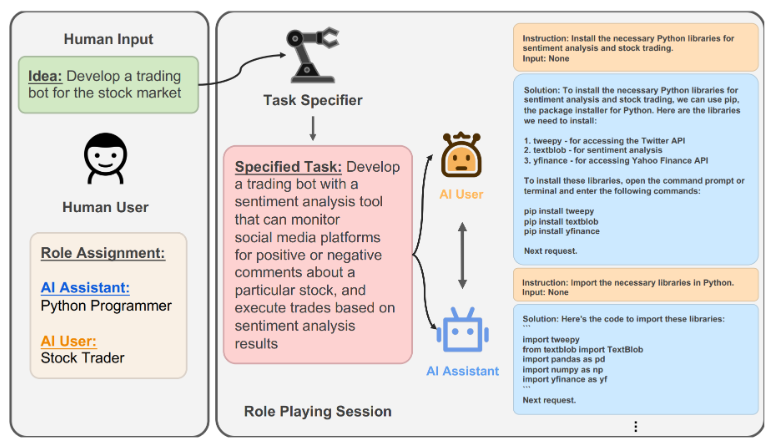

## 3.2 AI Popular Science E-book

### 3.2.1 Task setup
- Scenario setup: Create a popular science e-book on the psychology of procrastination for general readers, requiring both scientific rigor and good readability
- Agent roles:
  - Psychologist: Possesses deep theoretical foundation in psychology, familiar with cognitive behavioral science, neuroscience, and other related fields, able to provide professional academic insights and empirical research support
  - Writer: Has excellent writing skills and narrative ability, good at transforming complex academic concepts into vivid and easy-to-understand text, focusing on reader experience and content readability

In [ ]:
# pip install "camel-ai==0.2.75" colorama

### 3.2.2 Define Collaboration Task

In [1]:
from colorama import Fore
from camel.societies import RolePlaying
from camel.utils import print_text_animated
from camel.models import ModelFactory
from camel.types import ModelPlatformType
from dotenv import load_dotenv
import os

# Load LLM_MODEL_ID / LLM_API_KEY / LLM_BASE_URL from .env
load_dotenv()

# Create the model: DeepSeek through the OpenAI-compatible API
model = ModelFactory.create(
    model_platform=ModelPlatformType.OPENAI_COMPATIBLE_MODEL,
    model_type=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
    url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
    api_key=os.getenv("LLM_API_KEY"),
    model_config_dict={"extra_body": {"thinking": {"type": "disabled"}}},
)

# Define the collaboration task
task_prompt = """
Create a short e-book on "The Psychology of Procrastination" for general readers interested in psychology.
Requirements:
1. Content should be scientifically rigorous, based on empirical research
2. Language should be easy to understand, avoiding excessive professional terminology
3. Include practical improvement suggestions and case analysis
4. Length controlled at 1500-2000 words (the book uses 8000-10000)
5. Clear structure, including introduction, core chapters, and summary
"""

print(Fore.YELLOW + f"Collaboration task:\n{task_prompt}\n")

Collaboration task:

Create a short e-book on "The Psychology of Procrastination" for general readers interested in psychology.
Requirements:
1. Content should be scientifically rigorous, based on empirical research
2. Language should be easy to understand, avoiding excessive professional terminology
3. Include practical improvement suggestions and case analysis
4. Length controlled at 1500-2000 words (the book uses 8000-10000)
5. Clear structure, including introduction, core chapters, and summary




**Task_prompt** is the task specification for the entire collaboration. It is not only the goal we want to achieve but will also be used behind the scenes by CAMEL to generate "inception prompts", ensuring that the conversation between the two agents always revolves around this core goal

### 3.2.3 Initialize Role-playing society


In [2]:
# Initialize role-playing session
# AI writer as "user", responsible for proposing writing structure and requirements
# AI psychologist as "assistant", responsible for providing professional knowledge and content
role_play_session = RolePlaying(
    assistant_role_name="Psychologist",
    user_role_name="Writer",
    task_prompt=task_prompt,
    model=model,
    with_task_specify=False, # In this example, we directly use the given task_prompt
)

print(Fore.CYAN + f"Specific task description:\n{role_play_session.task_prompt}\n")

2026-10-29 21:41:43,919 - camel.societies.role_playing - WARNING - Model provided globally is set for all agents if not already specified in agent_kwargs.
2026-10-29 21:41:45,200 - root - WARNING - Invalid or missing `max_tokens` in `model_config_dict`. Defaulting to 999_999_999 tokens.
2026-10-29 21:41:45,204 - root - WARNING - Invalid or missing `max_tokens` in `model_config_dict`. Defaulting to 999_999_999 tokens.
Specific task description:

Create a short e-book on "The Psychology of Procrastination" for general readers interested in psychology.
Requirements:
1. Content should be scientifically rigorous, based on empirical research
2. Language should be easy to understand, avoiding excessive professional terminology
3. Include practical improvement suggestions and case analysis
4. Length controlled at 1500-2000 words (the book uses 8000-10000)
5. Clear structure, including introduction, core chapters, and summary




**RolePlaying** is a high-level API provided by CAMEL that encapsulates complex prompt engineering. We only need to pass in the names of the two roles and the task.  Therefore, we assign the "writer" responsible for planning structure to user_role_name and the "psychologist" responsible for providing professional knowledge to assistant_role_name

### 3.2.4 Start and Run Automated Conversation

In [3]:
# Start the collaboration
chat_turn_limit, n = 10, 0  # the book uses 30
# init_chat() returns the opening message that starts the conversation
input_msg = role_play_session.init_chat()

while n < chat_turn_limit:
    n += 1
    # step() drives one full round: the AI user and the AI assistant each speak once
    assistant_response, user_response = role_play_session.step(input_msg)

    # Stop if either side returned no message
    if assistant_response.msg is None or user_response.msg is None:
        break

    print_text_animated(Fore.BLUE + f"Writer (AI User):\n\n{user_response.msg.content}\n")
    print_text_animated(Fore.GREEN + f"Psychologist (AI Assistant):\n\n{assistant_response.msg.content}\n")

    # Check the task-completion flag
    if "<CAMEL_TASK_DONE>" in user_response.msg.content or "<CAMEL_TASK_DONE>" in assistant_response.msg.content:
        print(Fore.MAGENTA + "✅ E-book creation completed!")
        break

    # The assistant's reply becomes the input of the next round
    input_msg = assistant_response.msg

print(Fore.YELLOW + f"Total of {n} rounds of collaborative conversation")

Writer (AI User):

Instruction: Provide a detailed outline for the e-book "The Psychology of Procrastination," including the introduction, core chapters, and summary. For each section, briefly describe its purpose and key content.
Input: The e-book targets general readers interested in psychology, must be scientifically rigorous with empirical research, use accessible language, include practical suggestions and case analysis, and the main text should be 1500-2000 words (with the full book version at 8000-10000 words).
Psychologist (AI Assistant):

Solution: Here is a detailed outline for the e-book *The Psychology of Procrastination*, structured to meet all requirements: scientific rigor grounded in empirical research, accessible language for general readers, practical suggestions with case analysis, and a length calibrated to 1500–2000 words for the main text (with notes where the full 8000–10000-word version would expand). The outline includes the introduction, core chapters, and sum

"while" is the core of the loop
- The conversation is automatically initiated by the init_chat() method based on the task and roles, without the need to manually write an opening
- Each step of the loop drives a complete round of initeraction by calling step() , and uses the psychologist's output from the previous round as input for the next round, forming a chian of creation
- The entire process will continue until the preset conversation turn limit is reached, or automatically terminates after either agent outputs the task completion fla <CAMEL_TASK_DONE>

### 3.2.5 Collaboraation Process Demonstration
- Step 1: Framework Building and Goal Alignment in the early stages of the conversation, the "writer" agent plays the leading role, proposing initial ideas for the overall structure and chapter arrangement of the e-book. The "psychologist" reviews and supplements this framework from a professional perspective, ensuring that core academic modules are not omitted, thereby reaching consensus on the final output at the beginning of collaboration
- Step2 : Generating core knowledge and knowlege translation. Forming stable "request-response" loop.
  - Psychologist: providing the core knowledge and cite some empirical evidence
  - Writer: Translating the vague knowledge into specific and vivid examples
- Step3: Iterating and ensuring the quality: The "writer" focus on the fluency, logical coherence and language style of the articles ; The "psychologist" focus on the accuracy of facts ,ensuring the scientific accuracy of core knowledge is not lost during translation
- Step4: Summary and elevation: Both agents review the final e-book

## 3.3 Advantages and limitations

# CAMEL: Strengths and Limitations

## Strengths

| Strength | What it means | Where you see it in the e-book case |
|---|---|---|
| **Light architecture, heavy prompting** | Collaboration comes from carefully designed prompts, not from routing logic, state machines or distributed infrastructure | The whole case is one `RolePlaying` object and a `while` loop |
| **Role-playing** | Two complementary roles: an **AI User** that drives the task and gives instructions, and an **AI Assistant** that carries them out | The Writer (user) plans and instructs; the Psychologist (assistant) supplies the content |
| **Inception prompting** | Before the chat starts, `RolePlaying` gives both agents structured system prompts covering each agent's own role, its partner's role, the shared task and a communication protocol | `===== RULES OF USER =====` / `===== RULES OF ASSISTANT =====`, filled with `{user_role}`, `{assistant_role}` and `{task}` |
| **A built-in conversation protocol** | One instruction at a time (`Instruction:` / `Input:`), answered with `Solution: ... Next request.`; the user ends the task with `<CAMEL_TASK_DONE>` | Keeps the chat on track without any orchestration code |
| **Minimal code for emergent collaboration** | You define only the roles and the goal; planning, drafting and revising emerge from the dialogue | Stages such as framework-building, drafting and polishing appear without being scripted |
| **Optional extras** | Task specification (`with_task_specify`), a critic in the loop (`critic_role_name`, `with_critic_in_the_loop`) and multi-agent `Workforce` | `with_task_specify=True` rewrites the task into a more detailed plan before the chat starts |
| **Broad ecosystem** | Multimodal support, a built-in toolkit, many LLM backends, and interoperability with LangChain, CrewAI and AutoGen | DeepSeek connects through `ModelPlatformType.OPENAI_COMPATIBLE_MODEL`, and `model_config_dict` passes `extra_body` through |

## Limitations

| Limitation | What it means |
|---|---|
| **Heavy dependence on prompt engineering** | Quality rests on the prompts; when collaboration goes wrong, it's hard to tell whether the role definition, the task description or the interaction rules are to blame, and different LLMs read the same prompt differently |
| **Limited scale** | Built around two agents: no conversation routing as in AutoGen, no distributed state as in AgentScope, and no arbitration when agents disagree |
| **Weak process control** | Steps emerge instead of being defined, so tasks that need strict, auditable workflows suit LangGraph better |
| **No grounding or fact-checking** | Only two LLMs talk to each other, with no search or retrieval. "Based on empirical research" can't be guaranteed, and citations may be hallucinated |
| **The output is a conversation, not a deliverable** | The e-book is scattered across the assistant's `Solution:` messages, and later revisions replace earlier drafts; you have to collect and assemble the final text yourself |
| **Fast-growing context and cost** | Both agents keep the full history, and the user often pastes the previous draft back as `Input:`, so tokens grow faster than the text itself |
| **Termination costs an extra call** | `step()` always runs both agents, so after the user says `<CAMEL_TASK_DONE>` the assistant still replies once before the loop stops |
| **Text-based termination** | The run stops only if `<CAMEL_TASK_DONE>` appears exactly; otherwise it runs until `chat_turn_limit` |
| **Slow demo output** | `print_text_animated` pauses 0.02 s per character, so long drafts take minutes just to print |
| **Fragile dependencies** | `camel-ai==0.2.75` downgrades openai (3.40 → 1.109.1) and pulls in `mcp` 2.x, which breaks its own import (`FastMCP`); you need to pin `"mcp<2"` and restart the kernel after installing |
| **The book and the repo disagree** | The env var is `LLM_MODEL` rather than `LLM_MODEL_ID`; `with_task_specify` is `False` in the book's code, but the book's log shows a specified task; the repo checks only the user's message for the completion flag |

## When to Choose CAMEL

| Good fit | Poor fit |
|---|---|
| Creative or exploratory work between two complementary experts (writing, brainstorming, research drafts) | Strict, auditable workflows with branches and checkpoints |
| Quick prototypes of agent collaboration with very little code | Large multi-agent systems or high concurrency |
| Studying emergent behavior and role-play prompting | Tasks that need verified facts, unless you add tools or retrieval |

## One-Line Summary

CAMEL turns a multi-agent system into a structured conversation between two role-played experts: the easiest way to get emergent collaboration, but it gives up control, grounding and scale, and the final result still has to be checked and assembled by you.

# 4.LangChain

## 4.1 The design of the framework


### 4.1.1 The structure of packages
- langchain-core: The base: message, prompt template, Runnable interface, Tool
- langchain: senior components: create_agent, structual output, middleware
- langchain-openai and other integration packages: Interfacing the specific supply service
- langgraph: is responsible for loop, state and memory when the create_agent is running
- LangSmith: visualize and trace

### 4.1.2 Core Acmponents
- Chat Model : the general interface for all models, HelloAgentLLM
- Mesge(system, human, AIM, Tool): Structural conversations, the dictionary of messages
- Prompt Template: the prompt with variables, REACT_PROMPT_TEMPLATE
- Runnable/LCEL: organize the components to be a chain
- TOol: generating descriptions and parameters schema for tools automatically, ToolExecutor.register(name,description,func)
- Agent(create_aagent): run the loop of "thinking->invocate->observe", ReActAgent.run(while loop and parser)
- Checkpoint: memory saved per conversation, self.history

### 4.1.3 The exchange rate assistant(LangChain)

In [15]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

# Load LLM_MODEL_ID / LLM_API_KEY / LLM_BASE_URL from .env
load_dotenv()

model = ChatOpenAI(
    model=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
    api_key=os.getenv("LLM_API_KEY"),
    base_url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
    temperature=0,
    extra_body={"thinking": {"type": "disabled"}},  # DeepSeek: turn off thinking mode
)

**You talk to the model with message objects, not dictionaries, and invoke returns an AIMessage.**

In [16]:
from langchain.messages import SystemMessage, HumanMessage

response = model.invoke([
    SystemMessage("You are a concise assistant."),
    HumanMessage("What is an exchange rate? Answer in one sentence."),
])
print(type(response).__name__)
print(response.content)

AIMessage
An exchange rate is the price at which one currency can be exchanged for another, expressing how much of one currency is needed to buy a unit of the other.


**The prompt template and LCEL chain**: LCEL is the core of langchain. Prompt templates, models and output parsers all implement the same Runnable interface, so you can join them with | like a pipe

In [17]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a travel currency assistant. Answer in one sentence."),
    ("human", "Which country or region uses {currency}?"),
])

chain = prompt | model | StrOutputParser()
print(chain.invoke({"currency": "JPY"}))

Japan uses JPY, which is the Japanese yen.


This chain does three things in turn:
- Prompt fills {currency:"jpy"} into the template and produces a list of messaages
- model calls Deepseek
- StrOutputParser pulls the plain text out of the returned AIMessage

**Tool definition**
- The function name becomes the tool name
- The docstring becomes the tool description. With parse_docstring=True, the Args: section also becomes a description for each parameter
- The type hints generate the parameter JSON schema automatically

In [18]:
import requests
from langchain.tools import tool


@tool(parse_docstring=True)
def get_exchange_rate(amount: float, base: str, quote: str) -> dict:
    """Convert an amount between two currencies using the latest published exchange rate.

    Args:
        amount: The amount of money to convert, e.g. 200.
        base: 3-letter code of the currency to convert from, e.g. "USD".
        quote: 3-letter code of the currency to convert to, e.g. "EUR".
    """
    base, quote = base.upper(), quote.upper()
    try:
        data = requests.get(f"https://open.er-api.com/v6/latest/{base}", timeout=15).json()
    except Exception as e:
        return {"error": f"Exchange-rate lookup failed: {e}"}
    if data.get("result") != "success":
        return {"error": f"Unsupported currency code '{base}'."}
    rate = data["rates"].get(quote)
    if rate is None:
        return {"error": f"Unsupported currency code '{quote}'."}
    return {
        "amount": amount,
        "base": base,
        "quote": quote,
        "rate": rate,
        "converted": round(amount * rate, 2),
        "updated": data["time_last_update_utc"],
        "source": "Rates By Exchange Rate API (https://www.exchangerate-api.com)",
    }


print(get_exchange_rate.name)
print(get_exchange_rate.description)
print(get_exchange_rate.args)
print(get_exchange_rate.invoke({"amount": 200, "base": "USD", "quote": "EUR"}))

get_exchange_rate
Convert an amount between two currencies using the latest published exchange rate.
{'amount': {'description': 'The amount of money to convert, e.g. 200.', 'title': 'Amount', 'type': 'number'}, 'base': {'description': '3-letter code of the currency to convert from, e.g. "USD".', 'title': 'Base', 'type': 'string'}, 'quote': {'description': '3-letter code of the currency to convert to, e.g. "EUR".', 'title': 'Quote', 'type': 'string'}}
{'amount': 200.0, 'base': 'USD', 'quote': 'EUR', 'rate': 0.895934, 'converted': 179.19, 'updated': 'Fri, 30 Oct 2026 00:02:31 +0000', 'source': 'Rates By Exchange Rate API (https://www.exchangerate-api.com)'}


**The Agent**
Create_agent is the standard way to build an anget in langchain. The frame work runs the "call model->run tools -> hand results back to the model" loop for you

In [19]:
from langchain.agents import create_agent

SYSTEM_PROMPT = """You are a travel currency assistant.
Always use the get_exchange_rate tool for rates and conversions; never guess a rate.
In your answer, give the converted amount, the rate, when the data was updated, and the source.
Mention that the result is an estimate and excludes exchange fees."""

agent = create_agent(
    model=model,
    tools=[get_exchange_rate],
    system_prompt=SYSTEM_PROMPT,
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "I have 200 USD. About how many euros is that? Also, how much is 10000 JPY in CNY?"}]
})

for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

I have 200 USD. About how many euros is that? Also, how much is 10000 JPY in CNY?
================================== Ai Message ==================================

I'll look up both rates for you.
Tool Calls:
  get_exchange_rate (call_00_44079aWhcmrq9ziSDTxo8055)
 Call ID: call_00_44079aWhcmrq9ziSDTxo8055
  Args:
    amount: 200
    base: USD
    quote: EUR
  get_exchange_rate (call_01_ppPlXdxRy1Yof725FLyK6750)
 Call ID: call_01_ppPlXdxRy1Yof725FLyK6750
  Args:
    amount: 10000
    base: JPY
    quote: CNY
================================= Tool Message =================================
Name: get_exchange_rate

{"amount": 200.0, "base": "USD", "quote": "EUR", "rate": 0.895934, "converted": 179.19, "updated": "Fri, 30 Oct 2026 00:02:31 +0000", "source": "Rates By Exchange Rate API (https://www.exchangerate-api.com)"}
================================= Tool Message =================================
Name: get

**The structual outputs**： we need a structural output if the final answer is for program, not for human: define a pydantic model, and pass it to reponse_format

In [20]:
from pydantic import BaseModel, Field
from langchain.agents.structured_output import ToolStrategy


class Conversion(BaseModel):
    """One currency conversion"""
    amount: float = Field(description="The original amount")
    base: str = Field(description="Currency converted from")
    quote: str = Field(description="Currency converted to")
    rate: float = Field(description="Exchange rate used")
    converted: float = Field(description="The converted amount")


class ConversionReport(BaseModel):
    """Final answer to the user's conversion request"""
    conversions: list[Conversion] = Field(description="Every conversion the user asked for")
    updated: str = Field(description="When the rates were last updated")
    source: str = Field(description="Where the rates came from")


structured_agent = create_agent(
    model=model,
    tools=[get_exchange_rate],
    system_prompt=SYSTEM_PROMPT,
    response_format=ToolStrategy(ConversionReport),
)

result = structured_agent.invoke({
    "messages": [{"role": "user", "content": "I have 200 USD. About how many euros is that? Also, how much is 10000 JPY in CNY?"}]
})

report = result["structured_response"]
print(type(report).__name__)
for c in report.conversions:
    print(f"{c.amount} {c.base} -> {c.converted} {c.quote} (rate {c.rate})")
print("Updated:", report.updated)

ConversionReport
200.0 USD -> 179.19 EUR (rate 0.895934)
10000.0 JPY -> 422.89 CNY (rate 0.042289)
Updated: Fri, 30 Oct 2026 00:02:31 +0000


**LangChain has two strategies for structured output:**
- providerStrategy uses the provider's native json_schema structured output
- ToolStrateegy turn the pydantic model into a tool, and the model hands over its answer by calling that tool. The same idea as AgentScope's generate_response 

**Memory:** create_agent has no memory by itself: every invoke is a brand-new conversation. To let it remember context, add a checkpointer and use a thread_id to tell conversations apart.

In [21]:
from langgraph.checkpoint.memory import InMemorySaver

memory_agent = create_agent(
    model=model,
    tools=[get_exchange_rate],
    system_prompt=SYSTEM_PROMPT,
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "trip-1"}}

memory_agent.invoke(
    {"messages": [{"role": "user", "content": "I have 200 USD. About how many euros is that?"}]},
    config,
)
result = memory_agent.invoke(
    {"messages": [{"role": "user", "content": "And how much is that in Japanese yen?"}]},
    config,
)

print(result["messages"][-1].content)
print("Messages in this thread:", len(result["messages"]))

**200 USD ≈ 31,576.32 JPY**

- **Rate:** 1 USD = 157.881601 JPY
- **Data updated:** Fri, 30 Oct 2026 00:02:31 UTC
- **Source:** Rates By Exchange Rate API (https://www.exchangerate-api.com)

So your 200 USD is roughly 179.19 EUR or about 31,576 JPY. As before, this is an estimate based on the latest published rate and excludes exchange fees or commissions.
Messages in this thread: 8


- InMemorySaver keeps memory only in RAM. so, it's gone when the process ends, for example when you restart the notebook kernel. In production, use a SQLite or Postgres checkpointer instead.
- A differnt thread_id starts a completely new conversation

**Streaming**: with stream_mode='updates', the agent hands you each step's update as soon as that step finishes:

In [22]:
for chunk in agent.stream(
    {"messages": [{"role": "user", "content": "How much is 50 GBP in USD?"}]},
    stream_mode="updates",
):
    for step, update in chunk.items():
        last = update["messages"][-1]
        print(f"[{step}] {type(last).__name__}: {last.content or last.tool_calls}")

[model] AIMessage: [{'name': 'get_exchange_rate', 'args': {'amount': 50, 'base': 'GBP', 'quote': 'USD'}, 'id': 'call_00_9stvUBhnQ9Th4voTc4Ln0725', 'type': 'tool_call'}]
[tools] ToolMessage: {"amount": 50.0, "base": "GBP", "quote": "USD", "rate": 1.334844, "converted": 66.74, "updated": "Fri, 30 Oct 2026 00:02:31 +0000", "source": "Rates By Exchange Rate API (https://www.exchangerate-api.com)"}
[model] AIMessage: **50 GBP ≈ 66.74 USD**

- **Exchange rate:** 1 GBP = 1.334844 USD
- **Data updated:** Fri, 30 Oct 2026 00:02:31 UTC
- **Source:** Rates By Exchange Rate API (https://www.exchangerate-api.com)

This is an estimate based on the latest published rate and excludes any exchange fees or commissions your bank or provider may charge.


# LangChain: Strengths and Limitations

## Strengths

| Strength | What it means | Where you see it in the currency case |
|---|---|---|
| **The largest ecosystem** | Ready-made integrations for model providers, vector stores, retrievers and tools | DeepSeek connects through `langchain-openai` with nothing more than `base_url` |
| **Standard interfaces** | Every model, prompt, parser and tool implements the same `Runnable` interface, so switching providers usually means changing one line | `ChatOpenAI(...)` could be swapped for another chat model without touching the rest |
| **LCEL composition** | Components join with the `\|` pipe, and each one's output becomes the next one's input | `prompt \| model \| StrOutputParser()` |
| **Tools from plain functions** | `@tool` turns the function name, docstring and type hints into the tool's name, description and JSON schema | `get_exchange_rate(amount, base, quote)` takes three typed parameters; no `"200 USD to EUR"` string, no regex |
| **Native function calling** | The model returns structured `tool_calls` instead of text, so there's no parser to write and no output format to dictate in the prompt | No `Thought:` / `Action:` rules in the system prompt |
| **Parallel tool calls** | One AI message can carry several tool calls, which cuts model round trips | Both conversions go out in one round: 2 model calls in total, against 3 rounds in Chapter 4 |
| **A complete agent in one call** | `create_agent` provides the tool loop, structured output, memory, streaming and middleware | One function call replaces Chapter 4's `ReActAgent`, parser and history handling |
| **Structured output** | `response_format` returns a pydantic object; `ToolStrategy` also works with providers that don't support `json_schema` | `result["structured_response"]` is a `ConversionReport` |
| **Built-in memory** | A checkpointer saves each conversation under a `thread_id` | The follow-up "And how much is that in Japanese yen?" is answered correctly |
| **Observability** | Streaming exposes each graph step, and LangSmith traces every call | `stream_mode="updates"` shows `[model]` → `[tools]` → `[model]` |
| **A path to LangGraph** | `create_agent` already returns a LangGraph graph, so you can drop down a level when you need more control | The node names `model` and `tools` |

## Limitations

| Limitation | What it means |
|---|---|
| **Many layers of abstraction** | When something breaks, you dig through `langchain`, `langchain-core`, an integration package and `langgraph` to find out why |
| **Fast API churn** | Older tutorial code no longer works: `AgentExecutor` and `langchain.chains.LLMChain` fail to import in 1.4.7 |
| **Hidden control flow** | The agent loop runs inside the framework; for precise control over every step you need LangGraph |
| **A dangerous default step limit** | `recursion_limit` defaults to 10007. If the model never calls the structured-output tool, the agent keeps calling the model (in my test it ran 5 minutes without stopping), so always set a limit |
| **Strategy depends on the model name** | Without an explicit `ToolStrategy`, the model name decides between `json_schema` and tool calling, so behavior can change quietly behind a proxy or after a rename |
| **No visible reasoning** | Native function calling doesn't ask the model for a Thought, so you see what it did but not why |
| **Context only grows** | With memory, every tool result stays in the history; you need something like `SummarizationMiddleware` to keep length and cost under control |
| **Memory is in-RAM by default** | `InMemorySaver` is lost when the process or kernel restarts; production needs a SQLite or Postgres checkpointer |
| **Dependency conflicts** | `langchain-openai` 1.7.3 requires `openai>=2.45`, which can't coexist with `camel-ai` 0.2.75 (`openai<2`) |

## Compared with the Chapter 4 Hand-Written ReAct

| | Chapter 4 hand-written ReAct | LangChain `create_agent` |
|---|---|---|
| Tool-call format | `Thought:` / `Action: Tool[input]`, defined in the prompt | Native function calling, structured `tool_calls` |
| Parsing | Your own regexes | None needed |
| Tool parameters | A single string | Several typed parameters, schema generated automatically |
| Actions per round | One | Several, in parallel |
| Stop signal | `Finish[...]` | An AI message with no tool calls |
| Memory | A `self.history` list | A checkpointer plus `thread_id` |
| Step limit | `max_steps=5` | `recursion_limit` (default 10007) |

## When to Choose LangChain

| Good fit | Poor fit |
|---|---|
| Standard tool-using agents, RAG and chat apps built quickly | Workflows that need exact control over every branch and loop (use LangGraph) |
| Projects that need many integrations, or easy switching between models | Teams that want a small, stable API with minimal abstraction |
| Prototypes that may later grow into LangGraph graphs | Multi-agent role-play or large distributed agent systems |

## One-Line Summary

LangChain gives you the fastest route from a function and a prompt to a working agent, with tools, structured output, memory and streaming built in, but its many layers and fast-moving API hide the control flow, so set limits explicitly and step down to LangGraph when you need full control.

# 5.LangGraph

## 5.1 LangGraph Structure Overview

**Global state**: LangGraph models the agent's execution flow as a State Machine and represents it as a Directed Graph. In this paradigm, the the graph's Nodes represent specific computational steps (such as calling LLM, executing tools), while Edges define the transition logic from one node to another. The revolutionary aspect of this design is that it natively supports loops, making it unprecedentedly intuitive and simple to build complex agent workflows capable of iteration, reflection, and self-correction.

**Global State**: The entire graph's execution process revolves around a shared state object. TypedDict can contain any information you need to track, such as conversation history, intermediate results, iteration count. All nodes can read and update this central state

In [23]:
from typing import TypedDict, List

# Define global state data structure
class AgentState(TypedDict):
    messages: List[str]      # Conversation history
    current_task: str        # Current task
    final_answer: str        # Final answer
    # ... any other state to track

**Nodes**: Each node is a Python function that receives the current state as input and returns an updated state as output. Nodes are units that perform specific work.

In [24]:
# Define a "planner" node function
def planner_node(state: AgentState) -> AgentState:
    """Formulate a plan based on current task and update state."""
    current_task = state["current_task"]
    # ... call LLM to generate plan ...
    plan = f"Plan generated for task '{current_task}'..."

    # Append new message to state
    state["messages"].append(plan)
    return state

# Define an "executor" node function
def executor_node(state: AgentState) -> AgentState:
    """Execute latest plan and update state."""
    latest_plan = state["messages"][-1]
    # ... execute plan and get result ...
    result = f"Result of executing plan '{latest_plan}'..."

    state["messages"].append(result)
    return state

**Edges**: Edges are responsible for connecting nodes and defining the direction of the workflow. The simplest edge is a regular edge, which specifies that the output of one node always flows to another fixed node. LangGraph's most powerful feature lies in Conditional Edges. It uses a function to judge the current state and then dynamically decides which node to jump to next. This is the key to implementing loops and complex logical branches.

In [25]:
def should_continue(state: AgentState) -> str:
    """Condition function: decide next route based on state."""
    # Assume if messages are less than 3, need to continue planning
    if len(state["messages"]) < 3:
        # Returned string needs to match the key defined when adding conditional edge
        return "continue_to_planner"
    else:
        state["final_answer"] = state["messages"][-1]
        return "end_workflow"

After defining state,nodes and edges, we can assemble them into an executable workflow like building blocks

In [26]:
from langgraph.graph import StateGraph, END

# Initialize a state graph and bind our defined state structure
workflow = StateGraph(AgentState)

# Add node functions to the graph
workflow.add_node("planner", planner_node)
workflow.add_node("executor", executor_node)

# Set graph entry point
workflow.set_entry_point("planner")

# Add regular edge, connecting planner and executor
workflow.add_edge("planner", "executor")

# Add conditional edge, implementing dynamic routing
workflow.add_conditional_edges(
    # Starting node
    "executor",
    # Judgment function
    should_continue,
    # Route mapping: map judgment function's return value to target node
    {
        "continue_to_planner": "planner", # If returns "continue_to_planner", jump back to planner node
        "end_workflow": END               # If returns "end_workflow", end process
    }
)

# Compile graph, generate executable application
app = workflow.compile()

# Run graph
inputs = {"current_task": "Analyze recent AI industry news", "messages": []}
for event in app.stream(inputs):
    print(event)

{'planner': {'messages': ["Plan generated for task 'Analyze recent AI industry news'..."], 'current_task': 'Analyze recent AI industry news'}}
{'executor': {'messages': ["Plan generated for task 'Analyze recent AI industry news'...", "Result of executing plan 'Plan generated for task 'Analyze recent AI industry news'...'..."], 'current_task': 'Analyze recent AI industry news'}}
{'planner': {'messages': ["Plan generated for task 'Analyze recent AI industry news'...", "Result of executing plan 'Plan generated for task 'Analyze recent AI industry news'...'...", "Plan generated for task 'Analyze recent AI industry news'..."], 'current_task': 'Analyze recent AI industry news'}}
{'executor': {'messages': ["Plan generated for task 'Analyze recent AI industry news'...", "Result of executing plan 'Plan generated for task 'Analyze recent AI industry news'...'...", "Plan generated for task 'Analyze recent AI industry news'...", "Result of executing plan 'Plan generated for task 'Analyze recent AI

## 5.2 Rate exchange example

- Understand: analyze the user's query intent
- Search: simulate searching for information related to the intent
- Answer: generate the final answer based on the intent and searched information

**Intialize**

In [27]:
import os
from typing import TypedDict, Annotated

import requests
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver

# Load LLM_MODEL_ID / LLM_API_KEY / LLM_BASE_URL from .env
load_dotenv()

# Initialize the model that drives every node
llm = ChatOpenAI(
    model=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
    api_key=os.getenv("LLM_API_KEY"),
    base_url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
    temperature=0,
    extra_body={"thinking": {"type": "disabled"}},  # DeepSeek: turn off thinking mode
)

**Define the global state** : define a global state throught the whole workflow. It can share data structure between differents nodes, the continus content in workflow

In [28]:
class CurrencyState(TypedDict):
    messages: Annotated[list, add_messages]  # Conversation history (new messages are appended)
    understanding: str   # What the user wants, summarized by the LLM
    amount: float        # Amount to convert
    base: str            # Currency to convert from
    quote: str           # Currency to convert to
    rate_info: dict      # Result of the exchange-rate lookup
    final_answer: str    # Final generated answer
    step: str            # Mark current step

Annotated[list,add_messages]: the new message returned by the node would append to the tail of history ,not cover the whole list. Other lists are common, every update would replace the old one

**The node of workflow**: Understand the client's query.

In [29]:
class ConversionRequest(BaseModel):
    """The currency conversion the user is asking for"""
    understanding: str = Field(description="One sentence summarizing what the user wants")
    amount: float = Field(description="Amount to convert; use 1 if the user only asks for the rate")
    base: str = Field(description="3-letter code of the currency to convert from, e.g. USD")
    quote: str = Field(description="3-letter code of the currency to convert to, e.g. EUR")


parser_llm = llm.with_structured_output(ConversionRequest, method="function_calling")


def understand_query_node(state: CurrencyState) -> dict:
    """Step 1: Understand the request and extract the amount and currencies"""
    history = "\n".join(f"{m.type}: {m.content}" for m in state["messages"])
    prompt = f"""Read the conversation and work out the currency conversion the user wants now.
Use earlier turns to resolve words like "that" or "it".

Conversation:
{history}"""

    request = parser_llm.invoke([SystemMessage(content=prompt)])

    return {
        "understanding": request.understanding,
        "amount": request.amount,
        "base": request.base.upper(),
        "quote": request.quote.upper(),
        "step": "understood",
        "messages": [AIMessage(content=f"I understand: {request.understanding}")],
    }

In [30]:
def rate_lookup_node(state: CurrencyState) -> dict:
    """Step 2: Look up the exchange rate (replaces the book's Tavily search)"""
    amount, base, quote = state["amount"], state["base"], state["quote"]
    print(f"🔍 Looking up: {amount} {base} -> {quote}")

    try:
        data = requests.get(f"https://open.er-api.com/v6/latest/{base}", timeout=15).json()
        if data.get("result") != "success":
            raise ValueError(f"Unsupported currency code '{base}'")
        rate = data["rates"].get(quote)
        if rate is None:
            raise ValueError(f"Unsupported currency code '{quote}'")

        rate_info = {
            "rate": rate,
            "converted": round(amount * rate, 2),
            "updated": data["time_last_update_utc"],
            "source": "Rates By Exchange Rate API (https://www.exchangerate-api.com)",
        }
        return {
            "rate_info": rate_info,
            "step": "looked_up",
            "messages": [AIMessage(content="✅ Rate found! Preparing your answer...")],
        }

    except Exception as e:
        print(f"❌ Lookup failed: {e}")
        return {
            "rate_info": {"error": str(e)},
            "step": "lookup_failed",
            "messages": [AIMessage(content="❌ The rate lookup failed.")],
        }

In [31]:
def generate_answer_node(state: CurrencyState) -> dict:
    """Step 3a: Answer from the looked-up rate"""
    info = state["rate_info"]
    prompt = f"""Answer the user's currency question using only the data below.

User request: {state['understanding']}
Amount: {state['amount']} {state['base']}
Rate: 1 {state['base']} = {info['rate']} {state['quote']}
Converted amount: {info['converted']} {state['quote']}
Updated: {info['updated']}
Source: {info['source']}

Give the converted amount, the rate, when the data was updated, and the source.
Mention that the result is an estimate and excludes exchange fees."""

    response = llm.invoke([SystemMessage(content=prompt)])
    return {
        "final_answer": response.content,
        "step": "completed",
        "messages": [AIMessage(content=response.content)],
    }


def fallback_node(state: CurrencyState) -> dict:
    """Step 3b: The lookup failed, so explain instead of guessing a rate"""
    prompt = f"""The exchange-rate lookup failed with this error: {state['rate_info']['error']}

User request: {state['understanding']}

Tell the user the rate could not be retrieved and explain the likely reason.
Ask them to check the currency codes. Do not guess or invent an exchange rate."""

    response = llm.invoke([SystemMessage(content=prompt)])
    return {
        "final_answer": response.content,
        "step": "completed",
        "messages": [AIMessage(content=response.content)],
    }

**Constructing the graph**: connect all the nodes. 

In [32]:
def route_after_lookup(state: CurrencyState) -> str:
    """Conditional edge: pick the next node from the lookup result"""
    return "answer" if state["step"] == "looked_up" else "fallback"


def create_currency_assistant():
    workflow = StateGraph(CurrencyState)

    # Add the nodes
    workflow.add_node("understand", understand_query_node)
    workflow.add_node("lookup", rate_lookup_node)
    workflow.add_node("answer", generate_answer_node)
    workflow.add_node("fallback", fallback_node)

    # Connect them: a straight line until the lookup, then a branch
    workflow.add_edge(START, "understand")
    workflow.add_edge("understand", "lookup")
    workflow.add_conditional_edges(
        "lookup",
        route_after_lookup,
        {"answer": "answer", "fallback": "fallback"},
    )
    workflow.add_edge("answer", END)
    workflow.add_edge("fallback", END)

    # Compile the graph with memory
    memory = InMemorySaver()
    return workflow.compile(checkpointer=memory)


app = create_currency_assistant()
print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	understand(understand)
	lookup(lookup)
	answer(answer)
	fallback(fallback)
	__end__([<p>__end__</p>]):::last
	__start__ --> understand;
	lookup -.-> answer;
	lookup -.-> fallback;
	understand --> lookup;
	answer --> __end__;
	fallback --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**Run**: ask(), all questions use a same thread_id, memory has real function

In [33]:
def ask(question: str, thread_id: str = "currency-chat"):
    """Run one question through the graph and print what each node did"""
    config = {"configurable": {"thread_id": thread_id}}
    print("=" * 60)
    for output in app.stream({"messages": [HumanMessage(content=question)]}, config=config, stream_mode="updates"):
        for node_name, node_output in output.items():
            latest = node_output["messages"][-1]
            if node_name in ("answer", "fallback"):
                print(f"\n💡 Final answer (from the {node_name} node):\n{latest.content}")
            else:
                print(f"[{node_name}] {latest.content}")
    print("=" * 60)

**Normal routing**

In [34]:
ask("I have 200 USD. About how many euros is that?")

[understand] I understand: The user wants to know how many euros 200 US dollars is worth.
🔍 Looking up: 200.0 USD -> EUR
[lookup] ✅ Rate found! Preparing your answer...

💡 Final answer (from the answer node):
Based on the data provided:

- **Converted amount:** 200.00 USD = **179.19 EUR**
- **Exchange rate:** 1 USD = 0.895934 EUR
- **Last updated:** Fri, 30 Oct 2026 00:02:31 +0000
- **Source:** Rates By Exchange Rate API (https://www.exchangerate-api.com)

Please note that this result is an estimate and excludes any exchange fees that may apply.


**The same thread, test memory**

In [35]:
ask("And how much is that in Japanese yen?")

[understand] I understand: The user wants to know how much 200 USD (the amount from the previous conversion) is in Japanese yen.
🔍 Looking up: 200.0 USD -> JPY
[lookup] ✅ Rate found! Preparing your answer...

💡 Final answer (from the answer node):
Based on the data provided:

- **Converted amount:** 200.00 USD = **31,576.32 JPY**
- **Exchange rate:** 1 USD = 157.881601 JPY
- **Last updated:** Fri, 30 Oct 2026 00:02:31 +0000
- **Source:** Rates By Exchange Rate API (https://www.exchangerate-api.com)

Please note that this result is an estimate and does not include any exchange fees or charges that may apply.


**If the currency does not exist, take the other branch of the conditional edge**

In [36]:
ask("How much is 100 XYZ in USD?")

[understand] I understand: The user wants to know how much 100 XYZ is in US dollars.
🔍 Looking up: 100.0 XYZ -> USD
❌ Lookup failed: Unsupported currency code 'XYZ'
[lookup] ❌ The rate lookup failed.

💡 Final answer (from the fallback node):
I wasn't able to retrieve an exchange rate for **XYZ**, so I can't tell you how much 100 XYZ is worth in US dollars.

The likely reason is that **"XYZ" isn't a recognized currency code**. Currency codes are standardized three-letter codes (ISO 4217), such as USD, EUR, GBP, JPY, etc., and "XYZ" doesn't correspond to any real currency in the exchange-rate system.

Could you double-check the currency code you meant? For example:
- Did you mean a specific national currency (e.g., **XAF**, **XOF**, **XPF**)?
- Or is "XYZ" a ticker/token from a specific platform that may need a different kind of lookup?

Once you confirm the correct code, I can look up the rate for you. I won't guess or make up a rate in the meantime.


**Check the state**

state = app.get_state({"configurable": {"thread_id": "currency-chat"}}).values
print("Last step:", state["step"])
print("Last request:", state["amount"], state["base"], "->", state["quote"])
print("Messages in this thread:", len(state["messages"]))

# LangGraph: Strengths and Limitations

## Strengths

| Strength | What it means | Where you see it in the currency case |
|---|---|---|
| **Explicit, controllable flow** | The whole workflow is drawn as a graph of state, nodes and edges, so you decide exactly what runs and in what order | `understand` → `lookup` → `answer` / `fallback` |
| **Conditional edges** | A routing function reads the state and picks the next node, which gives you real branches instead of `if` statements hidden inside nodes | `route_after_lookup` sends a failed lookup to `fallback` |
| **Native loops** | Edges can point backwards, so retry, reflection and "generate → test → fix" cycles are first-class | Homework 3: a `validate` node that sends bad currency codes back to `understand` |
| **A shared, typed state** | One `TypedDict` carries everything between nodes, and reducers control how each field merges | `messages: Annotated[list, add_messages]` appends; other fields overwrite |
| **Modular nodes** | Each node is a plain Python function that returns a partial update, easy to test, swap or reuse | The Tavily search node was replaced by `rate_lookup_node` without touching the rest of the graph |
| **Built-in memory and persistence** | A checkpointer saves the state per `thread_id`, and `get_state` lets you inspect it at any time | The follow-up "And how much is that in Japanese yen?" resolves "that" to 200 USD |
| **Observability** | `stream_mode="updates"` reports each node as it finishes, and `draw_mermaid()` renders the graph | `[understand]` → `[lookup]` → final answer; dotted lines mark conditional edges |
| **Human-in-the-loop** | You can pause the graph at a node for human review before it continues | Not used here, but a natural place would be before an irreversible action |
| **The foundation under LangChain** | `create_agent` is itself a LangGraph graph, so you can drop down to LangGraph whenever you need more control | The `model` and `tools` nodes from the LangChain lesson |

## Limitations

| Limitation | What it means |
|---|---|
| **More boilerplate** | State, nodes, edges and compilation must all be written out, even for simple tasks; you think about *how* to control the flow, not just *what* to do |
| **Little emergent behavior** | The flow is fixed in advance: reliable, but without the open-ended collaboration of conversational frameworks like AutoGen or CAMEL |
| **Harder debugging across the graph** | A bug can sit inside a node, in the state passed between nodes, or in a routing condition, so you need a global view of the whole graph |
| **Strict state rules that are easy to break** | Changes made inside a routing function are lost, and mutating `state` in place leaks into the caller's input; both bugs appear in the book's own 6.5.1 example |
| **Memory only works if you use it correctly** | A new `thread_id` per question, as in the book's case, makes the checkpointer useless |
| **Growing history** | With `add_messages`, every message, including status lines like "✅ Rate found!", stays in the state and inflates later prompts unless you trim or summarize |
| **Loops need limits** | A cycle without an exit condition and a `recursion_limit` can run far longer than intended |
| **Fast-moving versions** | The book's repo pins `langgraph==1.0.0a3` (an alpha); this lesson's code targets 1.2.18, so pin versions and check the API |

## Compared with LangChain `create_agent`

| | LangChain `create_agent` | LangGraph `StateGraph` |
|---|---|---|
| Who draws the graph | The framework (a fixed `model` ↔ `tools` loop) | You |
| Control over steps | The model decides which tool to call next | You decide, with nodes and conditional edges |
| State | A message list | Any `TypedDict` you design |
| Best for | Standard tool-using agents built quickly | Custom workflows with branches, loops, checkpoints and review steps |

## When to Choose LangGraph

| Good fit | Poor fit |
|---|---|
| Processes with clear steps, branches and exit conditions (approvals, risk checks, pipelines) | Tiny one-shot tasks where a single prompt or `create_agent` is enough |
| Agents that must retry, reflect or self-correct in loops | Open-ended role-play or brainstorming between agents |
| Production systems that need auditability, persistence and human review | Teams that want minimal code and don't need fine-grained control |

## One-Line Summary

LangGraph trades convenience for control: you spell out every state field, node and edge, and in return you get predictable, inspectable workflows with real branches, loops and memory. That makes it the framework of choice when reliability matters more than emergence.

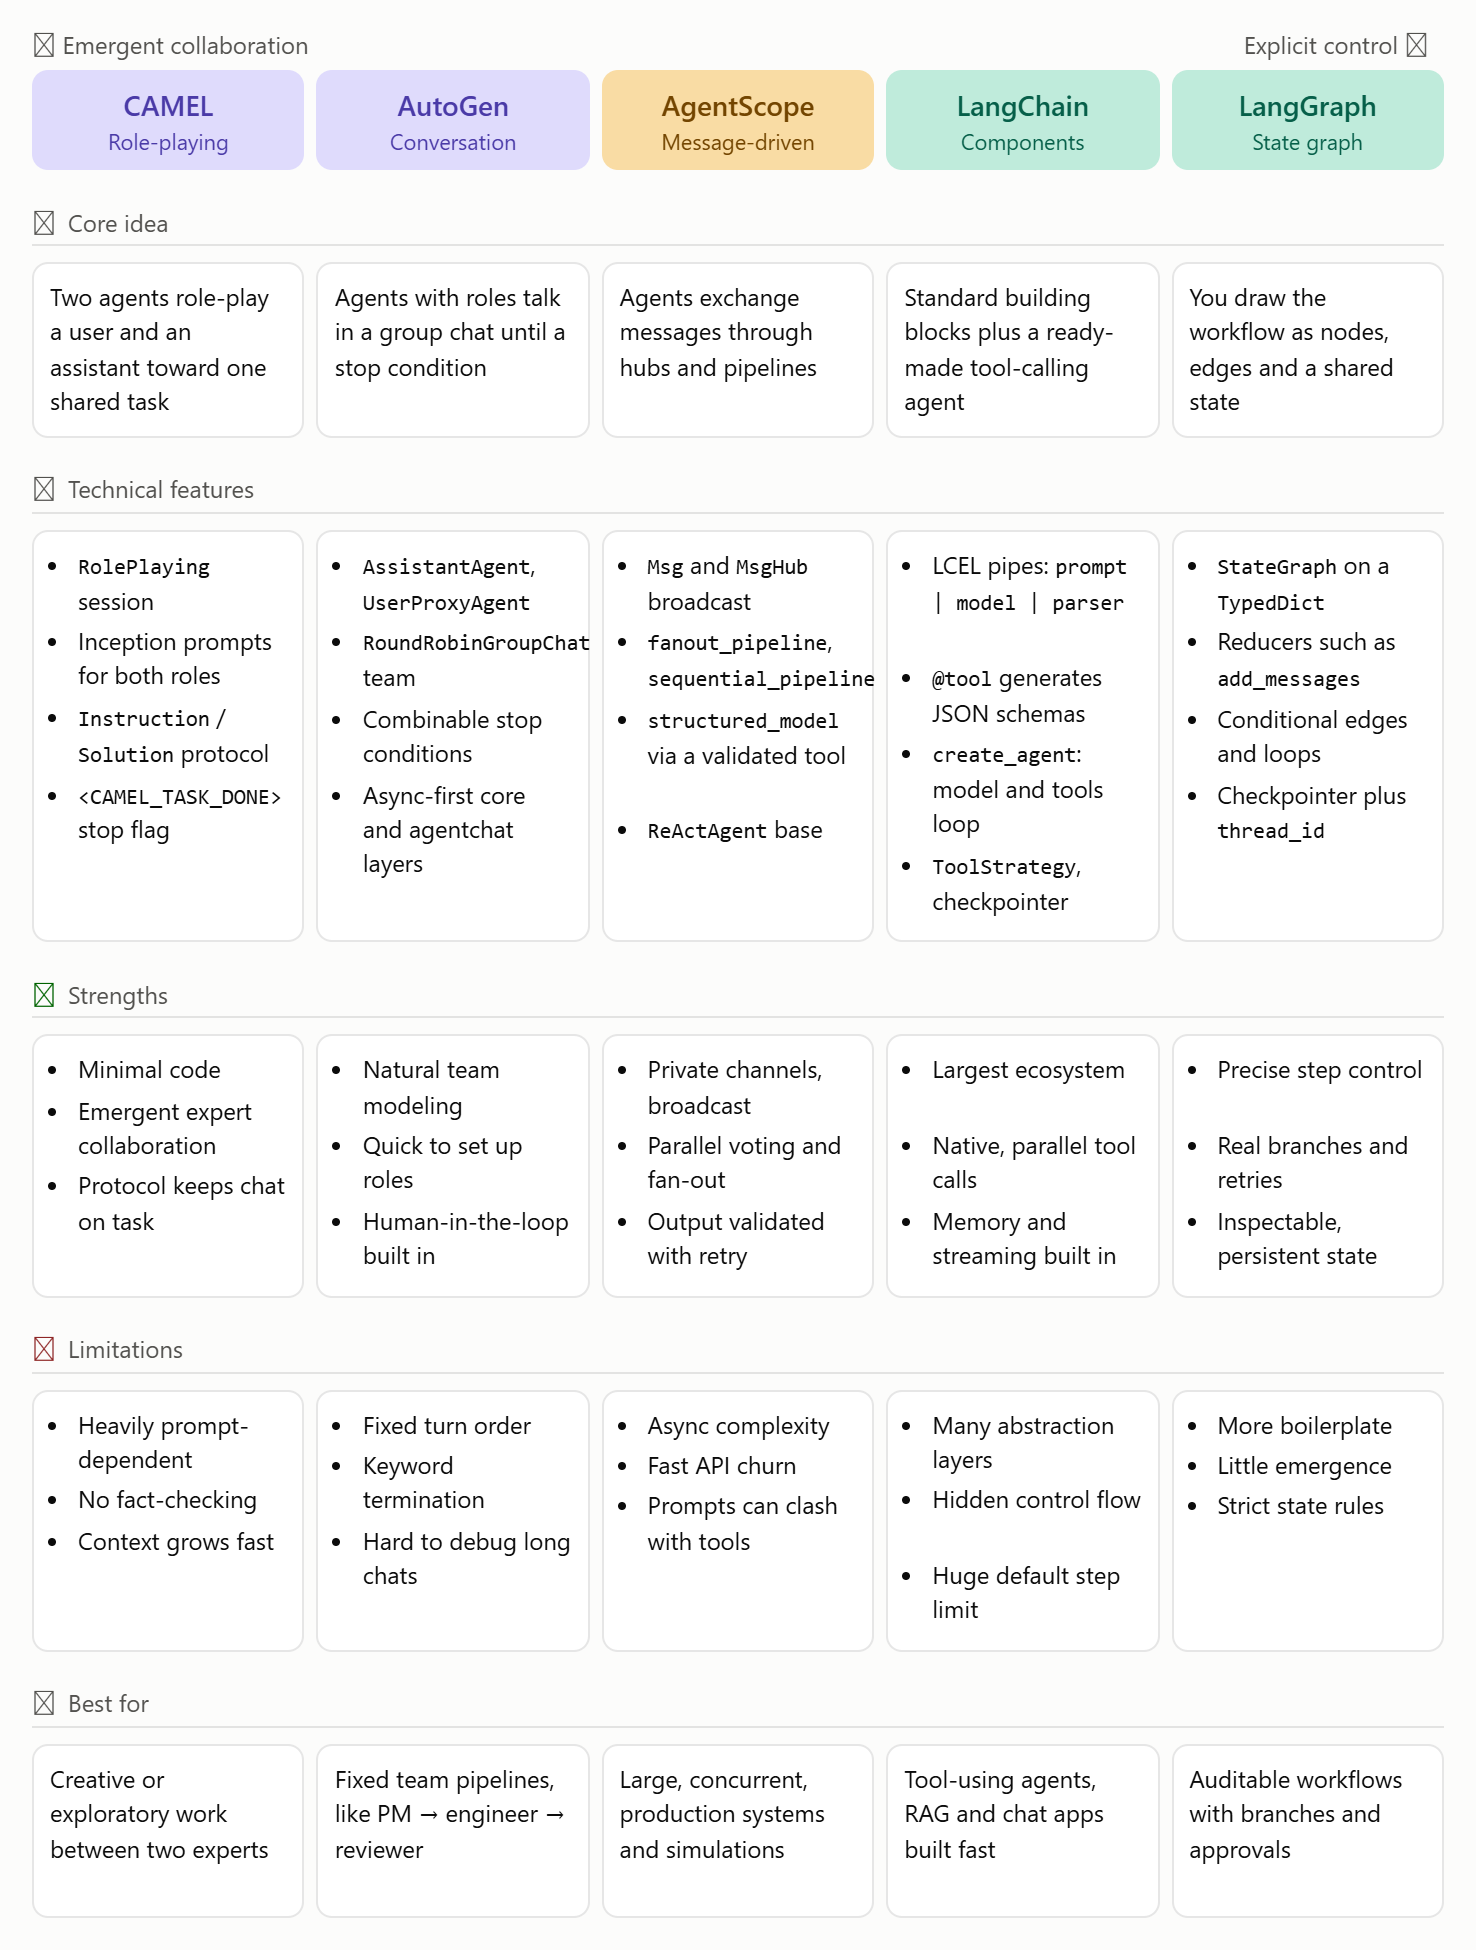